# 02 AI运维 - Linux的核心基础命令


## 本篇资料与学习路线

本篇对应 **AI运维8小时精华版 → PDF课件 → 第 2 份课件**，承接 01 的服务器与 Linux 入门，学习在终端中定位目录、管理文件、查找数据、编辑配置、查看日志和处理压缩包。

资料来源：[课程网盘](https://pan.baidu.com/s/1piPE1VDdCBoKDeGf-34QPA?pwd=1234)，提取码 `1234`。

主课件：**《2-0基础带你入行AI Linux运维_Linux的核心基础命令.pdf》**，共 **46 页**。已读取并核对全部 46 页的文字与页面预览。本篇依据课件整理，章节封面、重复总结与作业页归入对应主题，不是逐字视频转录。课件图已内嵌到 Notebook，页码按原课件顺序标注。

| 本篇主题 | 课件页码 | 对应视频目录 |
| --- | --- | --- |
| Linux 目录结构 | 2-5 | 10-Linux的目录结构.mp4 |
| 导航、创建与删除目录 | 6-14 | 11-基础命令_目录相关命令.mp4；12-基础命令_目录相关命令综合案例.mp4 |
| 文件操作 | 15-17 | 13-基础命令_文件操作命令.mp4 |
| 文件查找 | 18-20 | 14-基础命令_文件查找命令.mp4 |
| 日志管理与查找作业 | 21-23 | 15-基础命令_文件操作与查找综合练习.mp4 |
| vi/vim 与交换文件 | 24-33 | 16-基础命令_文件编辑命令.mp4；17-基础命令_文件编辑的常见错误.mp4 |
| 查看、筛选与统计文件 | 34-39 | 18-基础命令_文件查看命令.mp4 |
| 解压缩与项目目录作业 | 40-45 | 19-基础命令_文件解压缩命令.mp4 |

第 1 页是课程封面，第 46 页是结束页。**02 是第 2 份完整课件笔记**，不是只对应视频编号 02。

超出原课件的解释、纠正和答案标为 **“整理补充”**。示例采用 Linux 的 Bash 与常见 GNU 工具；Notebook 中的命令放在 Markdown 代码块内，供阅读或复制到 Linux 终端练习。

学习路线：目录与路径 → 导航 → 文件操作 → find → Vim → 日志查看 → 管道与统计 → 打包与解压 → 综合练习。


## 一、先看懂目录与终端

### 1.1 Linux 的目录是一棵树

**原课依据：第 3-5 页。** Linux 使用以 `/` 为起点的目录树，没有 Windows 中 `C:`、`D:` 这样的盘符路径写法。

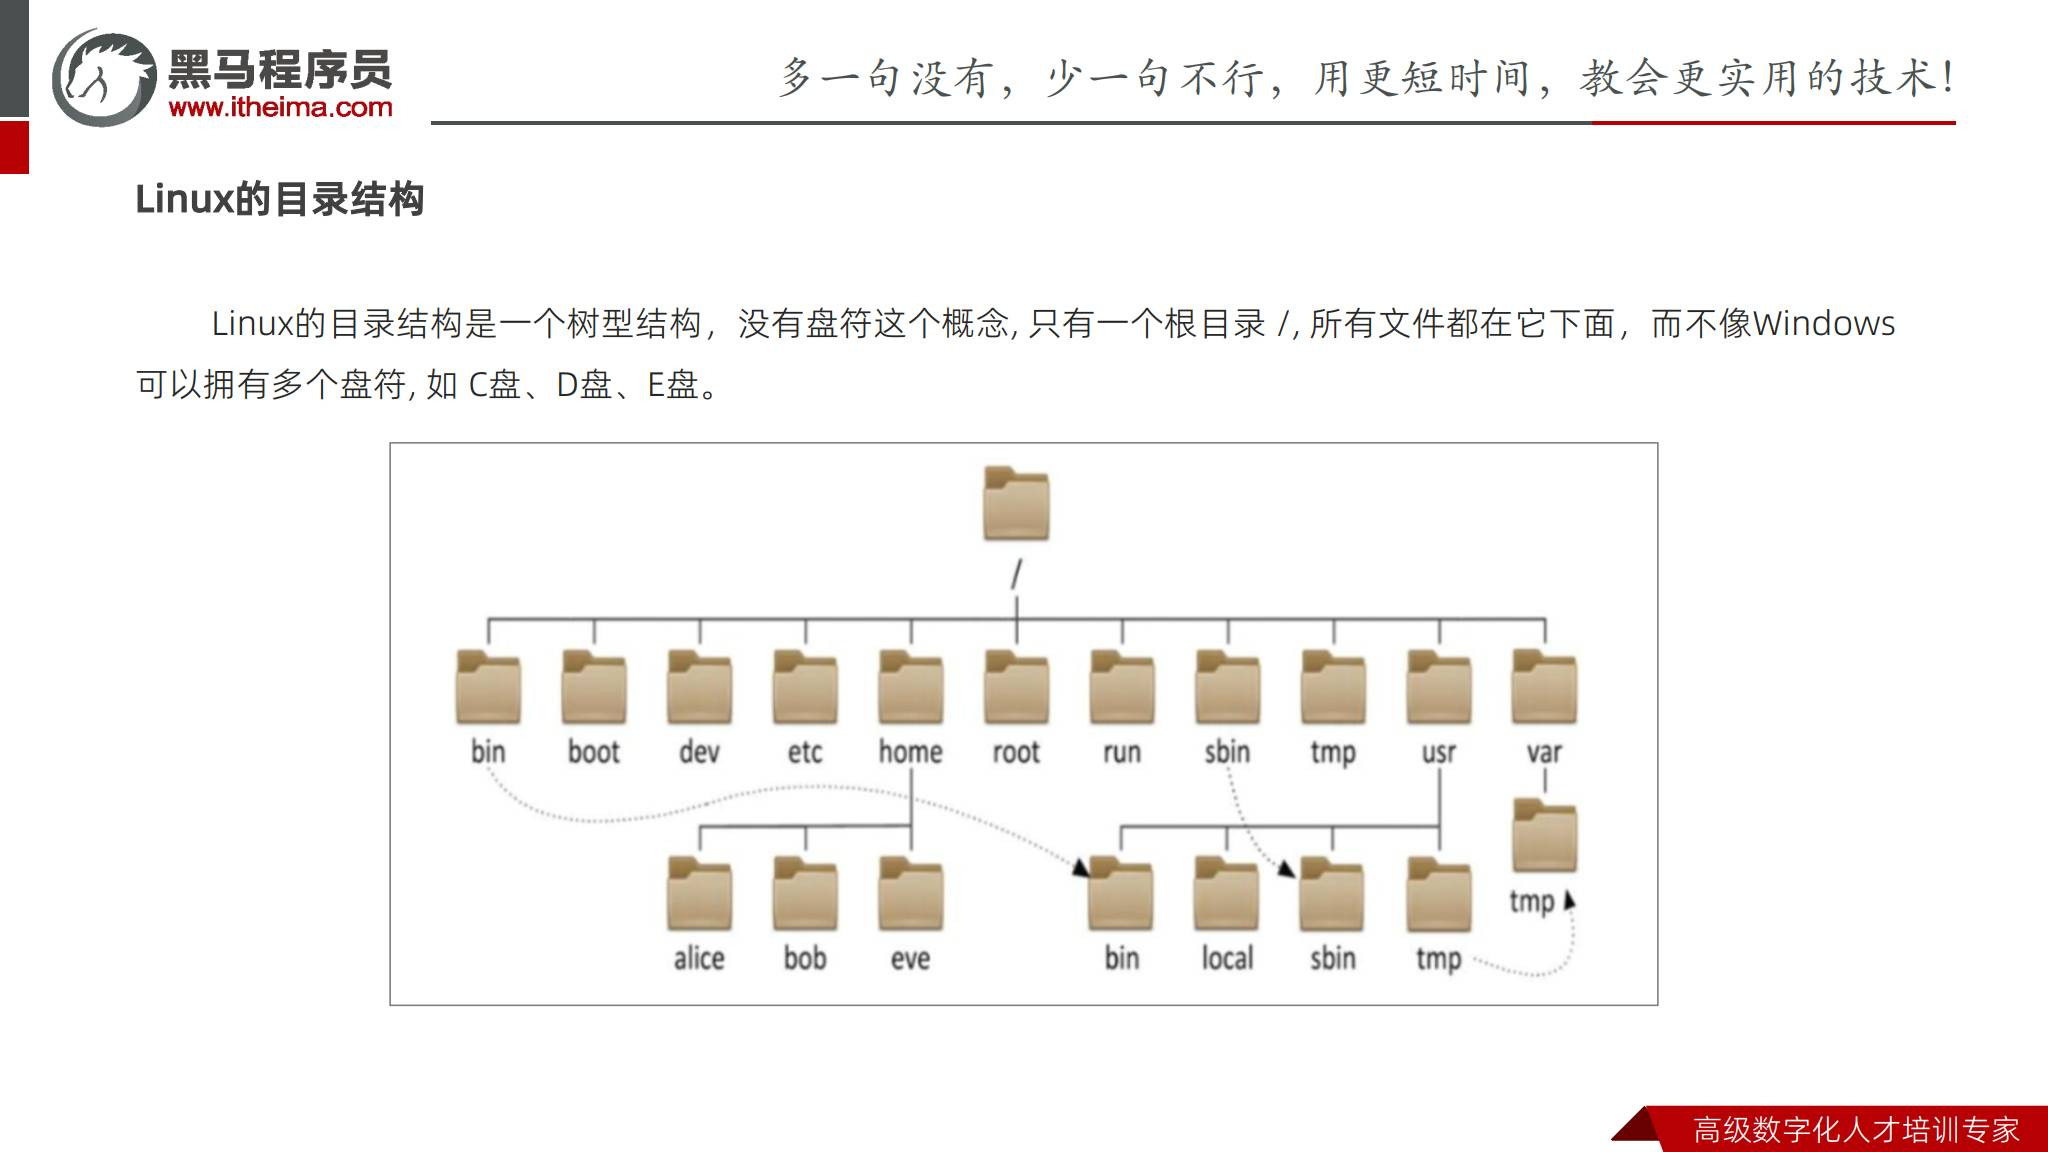

```text
/
├── etc        系统与软件配置
├── home       普通用户家目录的常见上级目录
├── root       root 用户的家目录
├── opt        可选或额外安装的软件
├── tmp        临时文件
├── usr        系统程序、库和共享数据
└── var        日志等经常变化的数据
```

**整理补充：** 这张树是帮助理解用途的简化示意，不代表每台机器都有完全相同的内容。多块磁盘也可以挂载到这棵树的某个目录下，不能把“没有盘符”理解成“只能使用一块磁盘”。


### 1.2 常见目录各自负责什么

**原课依据：第 4-5 页。**

| 目录 | 用途 | 理解要点 |
| --- | --- | --- |
| `/bin` | 常用命令程序 | 如 `ls`、`cp` 等，具体位置受发行版布局影响 |
| `/sbin` | 系统管理类命令 | 某些操作需要管理员权限；并非该目录的每个程序都只能由 root 执行 |
| `/home` | 普通用户家目录通常放在这里 | 例如 `/home/alice` 才是 alice 的家目录 |
| `/root` | root 用户家目录 | 与根目录 `/` 是两个不同概念 |
| `/opt` | 额外安装的软件及应用 | 课件后续会在这里组织项目目录 |
| `/tmp` | 临时文件 | **整理补充：不是回收站**，内容可能被自动清理 |
| `/usr` | 程序、库、文档等 | 不等同于用户家目录；系统软件也会使用它 |
| `/dev` | 设备文件 | 如磁盘、终端等设备对应的接口 |
| `/etc` | 系统和软件配置 | 并非所有软件配置都必须放在这里 |
| `/var/log` | 常见日志位置 | 日志文件名取决于发行版和日志服务 |

**整理补充：** CentOS Stream 9 等系统可能将 `/bin`、`/sbin` 链接到 `/usr/bin`、`/usr/sbin`。识别目录时看实际结构，不要机械套用旧系统截图。


### 1.3 终端提示符与命令格式

**原课依据：第 7 页。** 终端提供输入命令与查看输出的文本界面；Shell 负责解释命令。

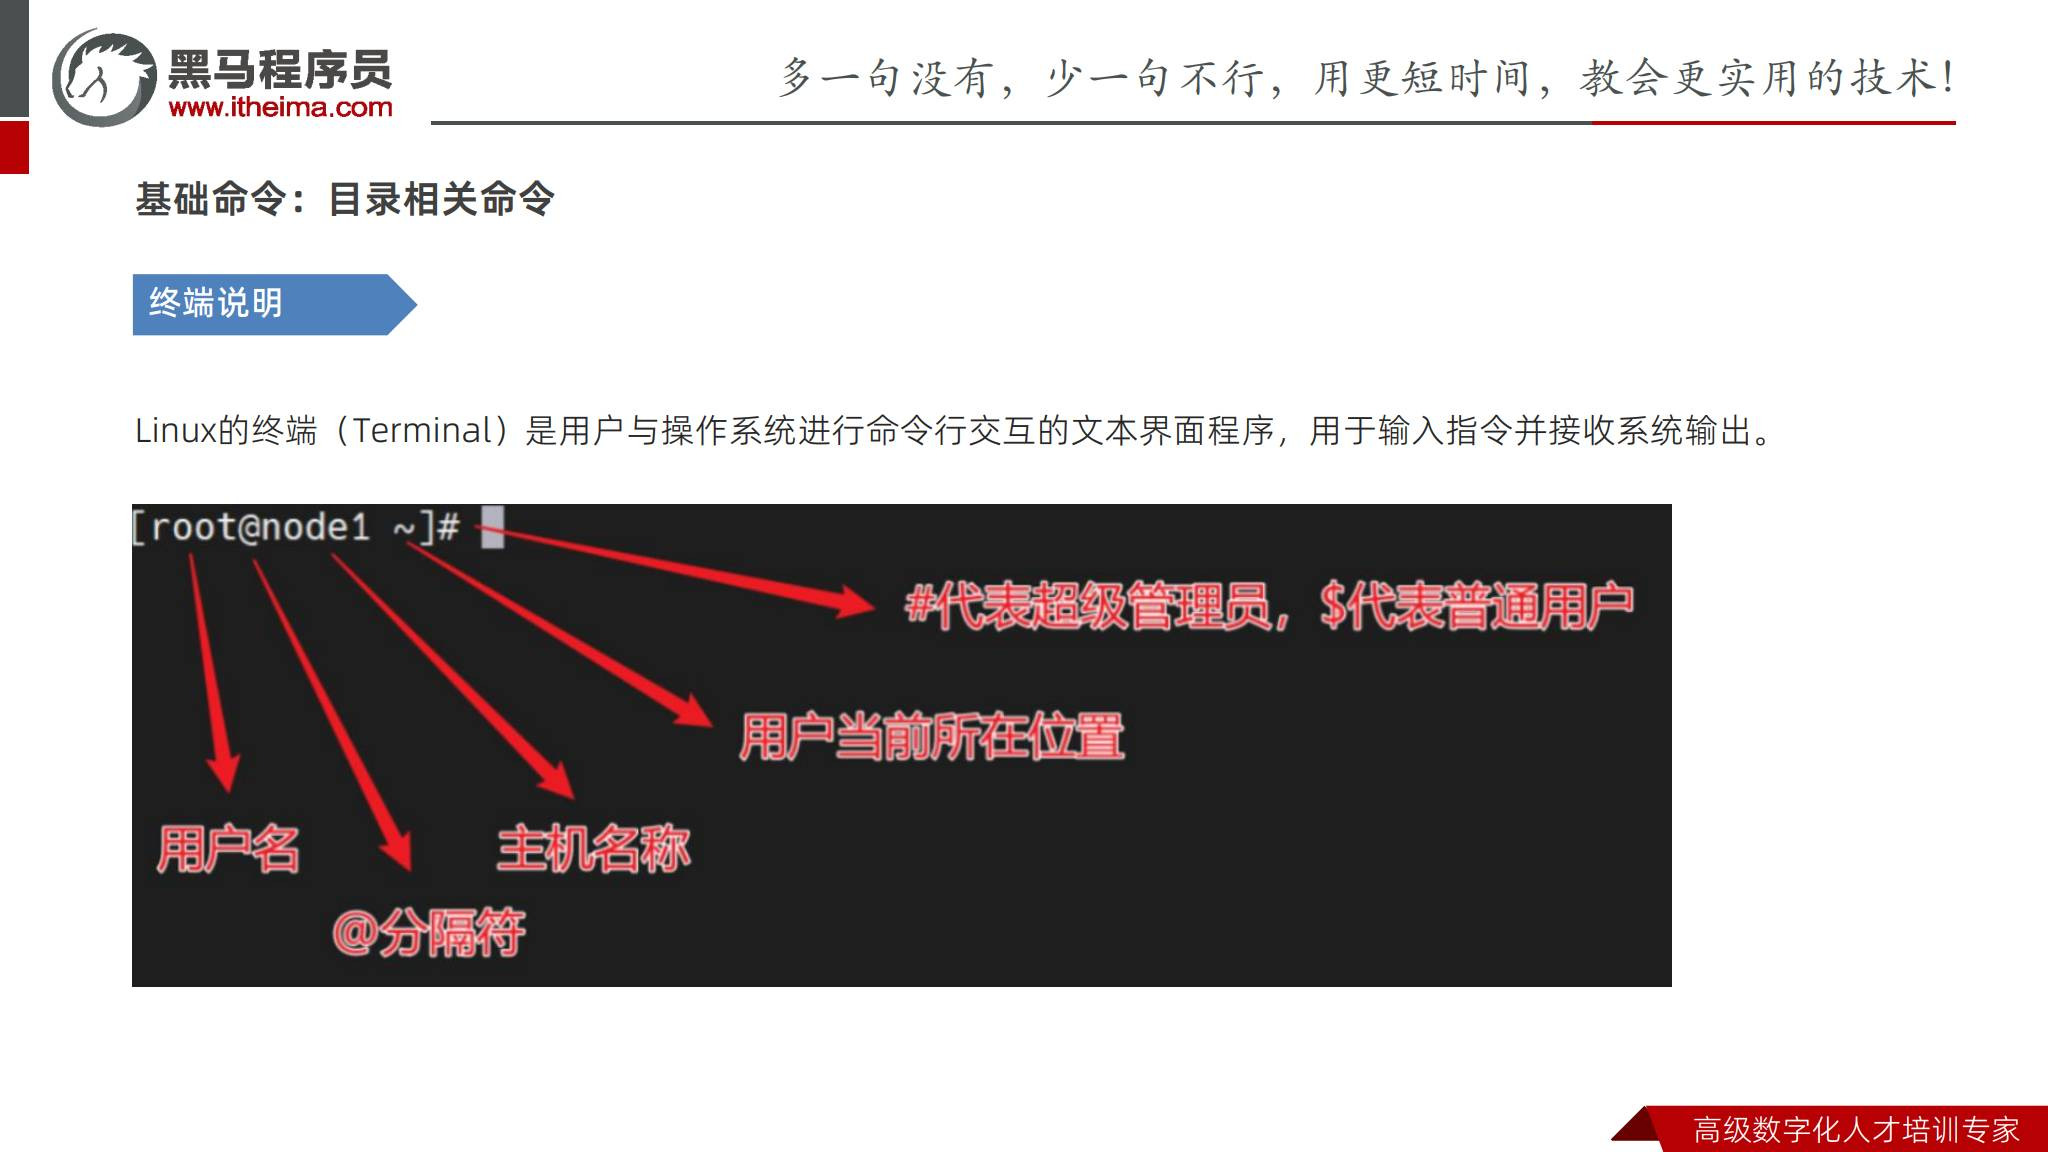

```text
[root@node1 ~]#
```

| 部分 | 含义 |
| --- | --- |
| `root` | 当前用户名 |
| `node1` | 主机名 |
| `~` | 当前用户的家目录 |
| `#` | 通常用于管理员提示符；普通用户常见 `$` |

**整理补充：** 提示符可以定制，身份可用 `whoami` 确认，位置可用 `pwd` 确认。输入命令时不复制提示符本身。

一般格式为：

```bash
命令 [选项] [参数]
ls -lh /etc
```

方括号表示“可选”，不需要原样输入。命令、选项和路径用空格分隔；大小写有意义，`-l` 是小写字母 L，`-1` 是数字 1。


### 1.4 绝对路径、相对路径与特殊写法

**原课依据：第 8-9 页；路径对比为整理补充。**

| 写法 | 含义 | 例子 |
| --- | --- | --- |
| `/` 开头 | 从根目录定位的绝对路径 | `/var/log` |
| 不以 `/` 开头 | 从当前目录定位的相对路径 | `logs/app.log` |
| `.` | 当前目录 | `./logs` |
| `..` | 上一级目录 | `../backup` |
| `~` | 当前用户的家目录 | `~/ai-ops-lab` |
| `-` | 在 `cd -` 中指上一次工作目录 | 不是通用于所有命令的路径缩写 |

如果当前位于 `/opt/web_project`，则 `logs/app.log` 对应 `/opt/web_project/logs/app.log`。执行 `cd /etc` 后，原来的相对路径不再指向同一个位置。

**整理补充：** Linux 文件名通常区分大小写。带空格的路径用引号，如 `cd "project notes"`。`"~/ai-ops-lab"` 中的 `~` 不会按家目录展开，可使用 `~/ai-ops-lab`。


## 二、目录相关命令

### 2.1 pwd 与 ls：我在哪里，这里有什么

**原课依据：第 8、13 页。**

| 命令 | 作用 |
| --- | --- |
| `pwd` | 显示当前工作目录 |
| `ls` | 列出当前目录内容 |
| `ls /etc` | 查看指定目录内容，当前目录不会因此改变 |
| `ls -a` | 包括以 `.` 开头的隐藏项 |
| `ls -l` | 长格式显示权限、属主、大小等信息 |
| `ls -lh` | 配合长格式，以便于阅读的单位显示大小 |
| `ls -lah` | 同时显示隐藏项、详细信息和易读大小 |

```bash
pwd
ls
ls -lah /var/log
```

**整理补充：** `ll` 常被配置成 `ls -l` 一类命令的别名，不是每个 Linux 环境都存在；若提示找不到 `ll`，使用 `ls -l`。`ls` 源于 list，记住用途即可。


### 2.2 cd：改变当前工作目录

**原课依据：第 9、13 页。**

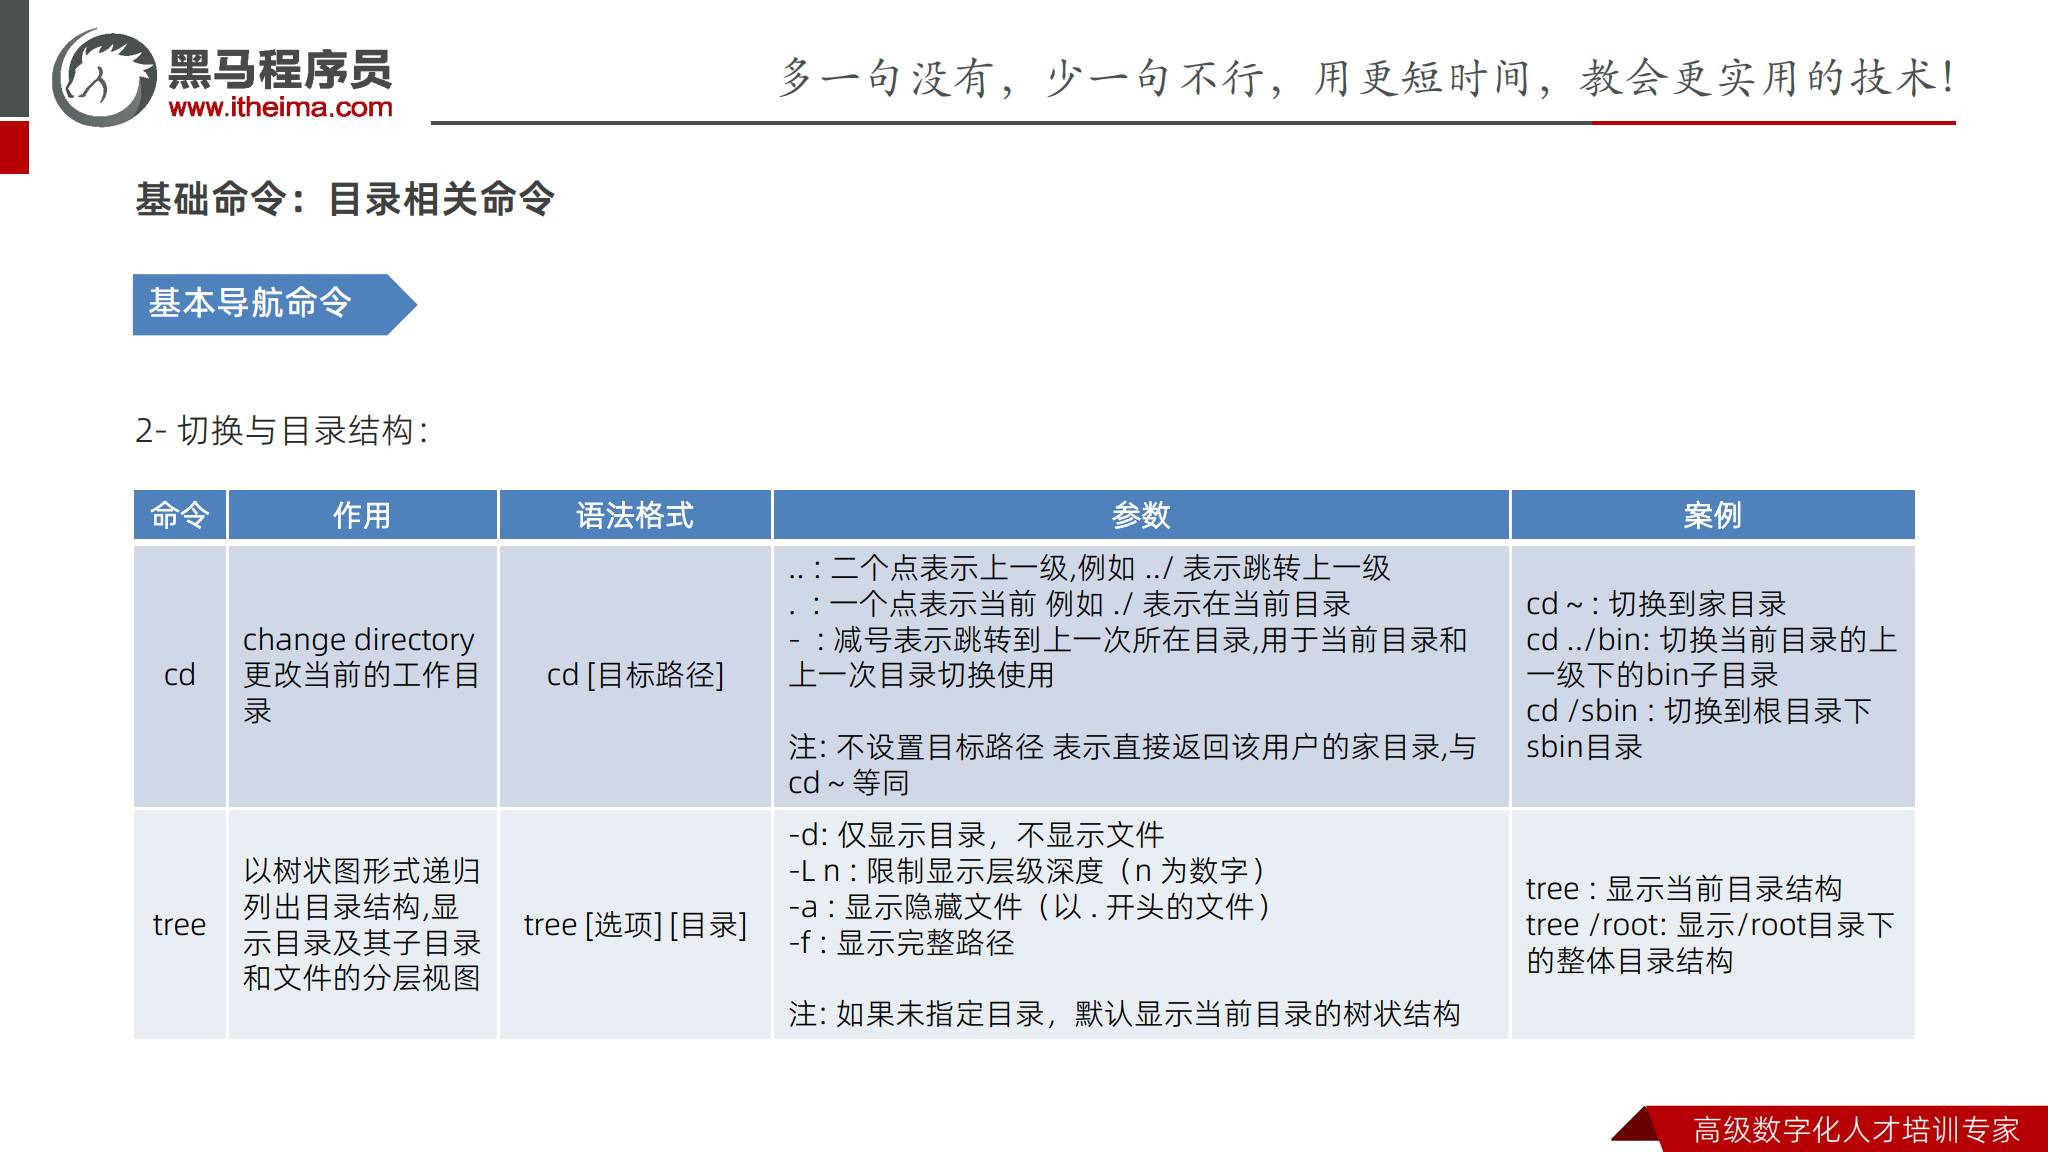

| 命令 | 结果 |
| --- | --- |
| `cd /etc` | 进入 `/etc` |
| `cd ..` | 进入上一级 |
| `cd ./logs` | 进入当前目录下的 logs |
| `cd ../bin` | 进入上一级下的 bin |
| `cd` 或 `cd ~` | 回到当前用户家目录 |
| `cd -` | 回到上一次工作目录，并通常输出目标路径 |

```bash
cd /etc
pwd
cd /var/log
pwd
cd -
pwd
```

**整理补充：** `cd` 一般是 Shell 内建命令，因为它需要改变当前 Shell 的工作目录。提示 `No such file or directory` 时先检查路径与大小写；提示 `Not a directory` 时，目标可能是文件。


### 2.3 tree、mkdir 与 rmdir

**原课依据：第 9-10、13 页。**

| 命令 | 作用与选项 |
| --- | --- |
| `tree [目录]` | 递归显示树形结构；默认查看当前目录 |
| `tree -d` | 只显示目录 |
| `tree -L 2` | 限制显示深度为 2 层 |
| `tree -a` | 包含隐藏项 |
| `tree -f` | 输出每个项目的路径 |
| `mkdir 目录` | 创建目录，父目录需已存在 |
| `mkdir -p a/b/c` | 创建缺少的多级目录；已存在的目录不因此报错 |
| `rmdir 目录` | 删除空目录 |
| `rmdir -p a/b/c` | 删除 c 后继续尝试删除变空的父目录 |

```bash
mkdir -p ~/ai-ops-lab/dirs/demo/child
tree -L 3 ~/ai-ops-lab/dirs
rmdir ~/ai-ops-lab/dirs/demo/child
```

**整理补充：** `rmdir` 不能删除含文件、隐藏项或子目录的非空目录。`tree` 可能需要安装；课件使用的 CentOS Stream 9 环境可在需要时由管理员执行 `sudo dnf install tree`。


### 2.4 原课综合练习：游戏存档目录

**原课依据：第 12 页。** 原题要求在根目录创建 `/game_saves`，包含 `level1`、`level2`、`backup/2023` 和 `backup/2024`，删除 2023 后再尝试删除整个 game_saves，观察错误。

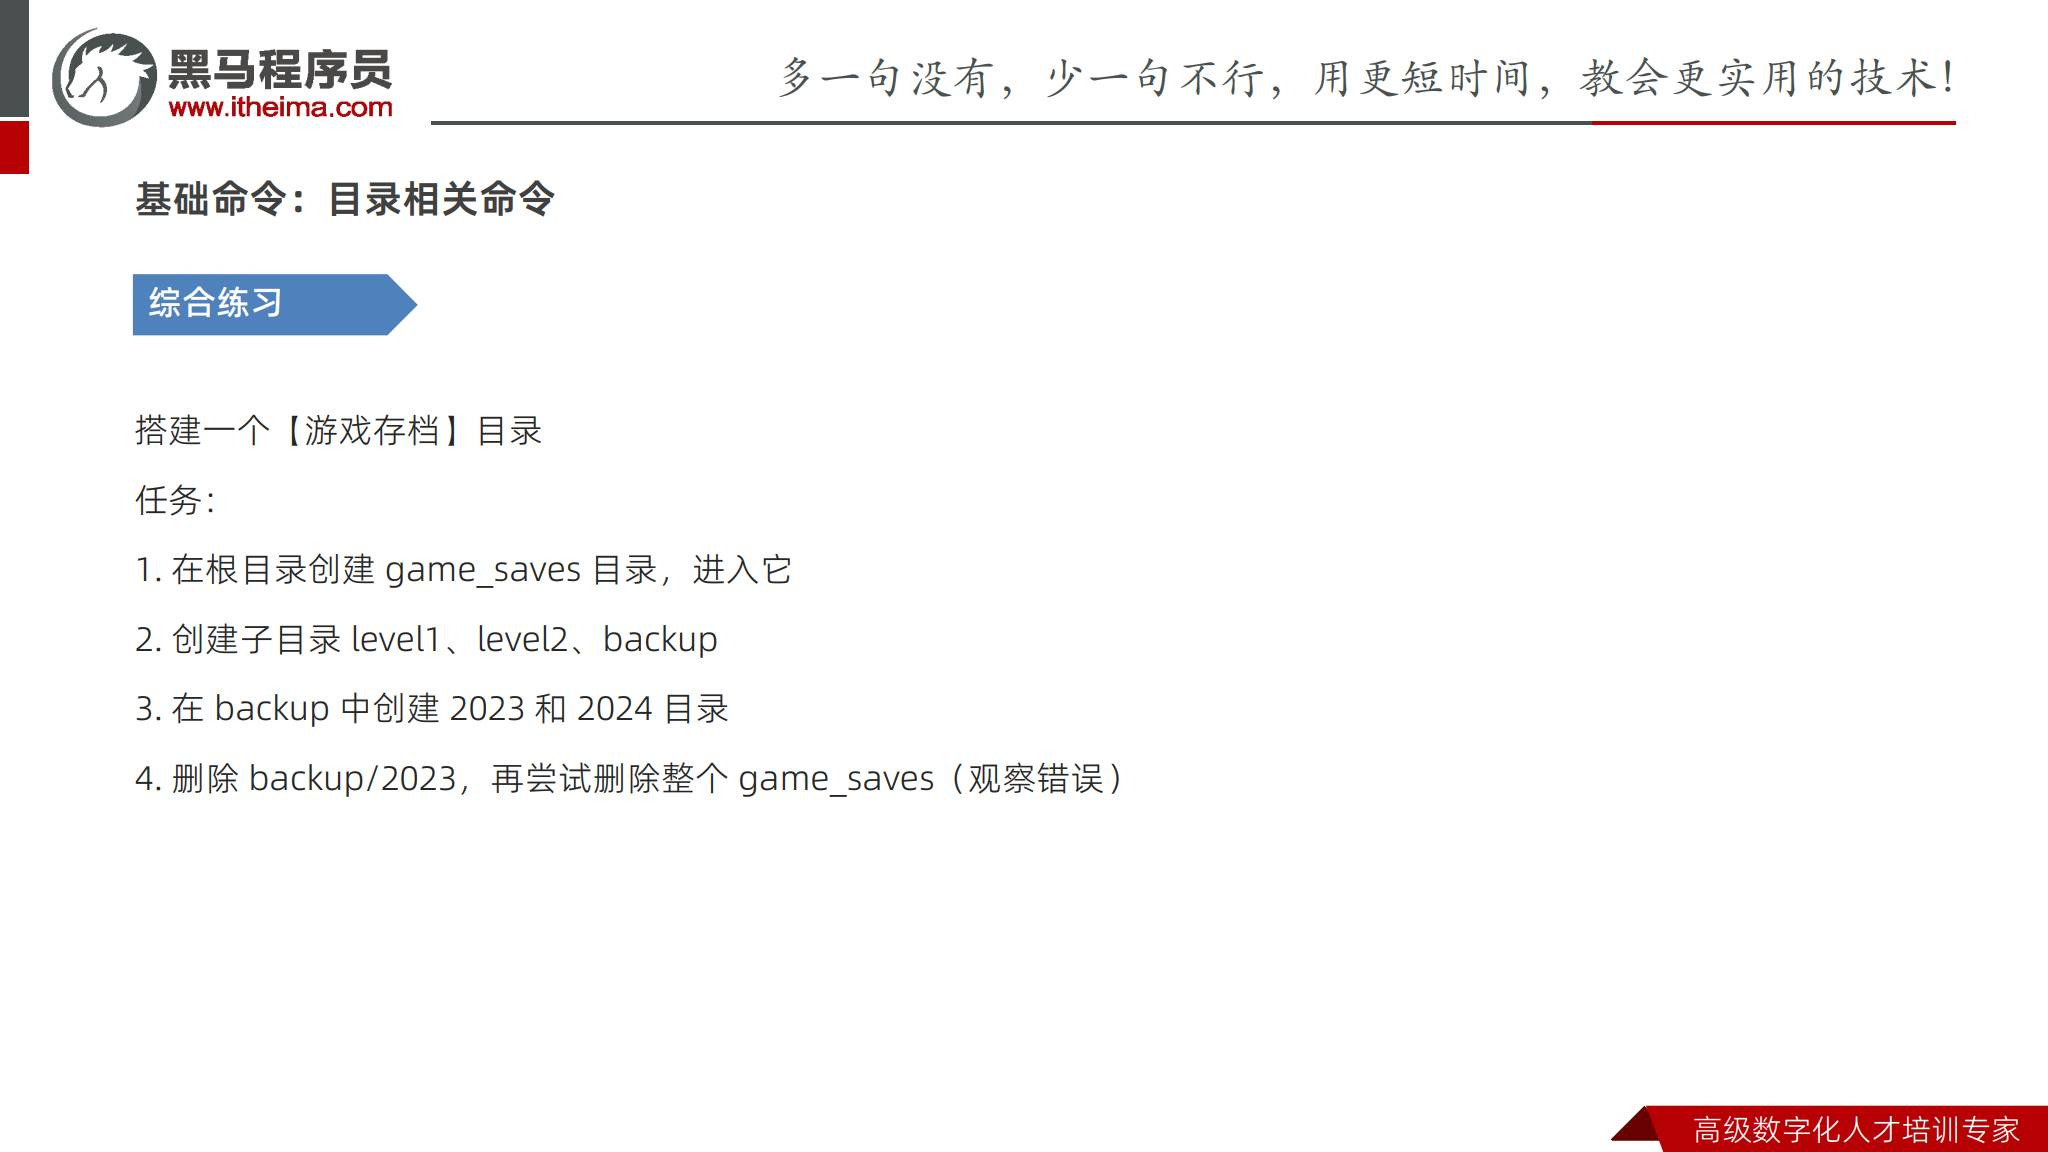

**整理补充答案：** 下面在个人练习目录中复现同样的结构，路径由原题的 `/game_saves` 改为 `~/ai-ops-lab/dirs/game_saves`，普通用户即可练习。

```bash
mkdir -p ~/ai-ops-lab/dirs/game_saves
cd ~/ai-ops-lab/dirs/game_saves
mkdir level1 level2 backup
mkdir backup/2023 backup/2024
tree .
rmdir backup/2023
cd ..
rmdir game_saves
```

最后一步预计失败，因为 game_saves 中还有其他目录。用 `ls -a game_saves` 或 `tree game_saves` 验证。

只用本节已经学过的删除命令，需先删除空叶子目录，再删除父目录：

```bash
rmdir game_saves/level1 game_saves/level2 game_saves/backup/2024
rmdir game_saves/backup
rmdir game_saves
```


### 2.5 原课作业：family 目录

**原课依据：第 14 页，目录结构来自课件截图。**

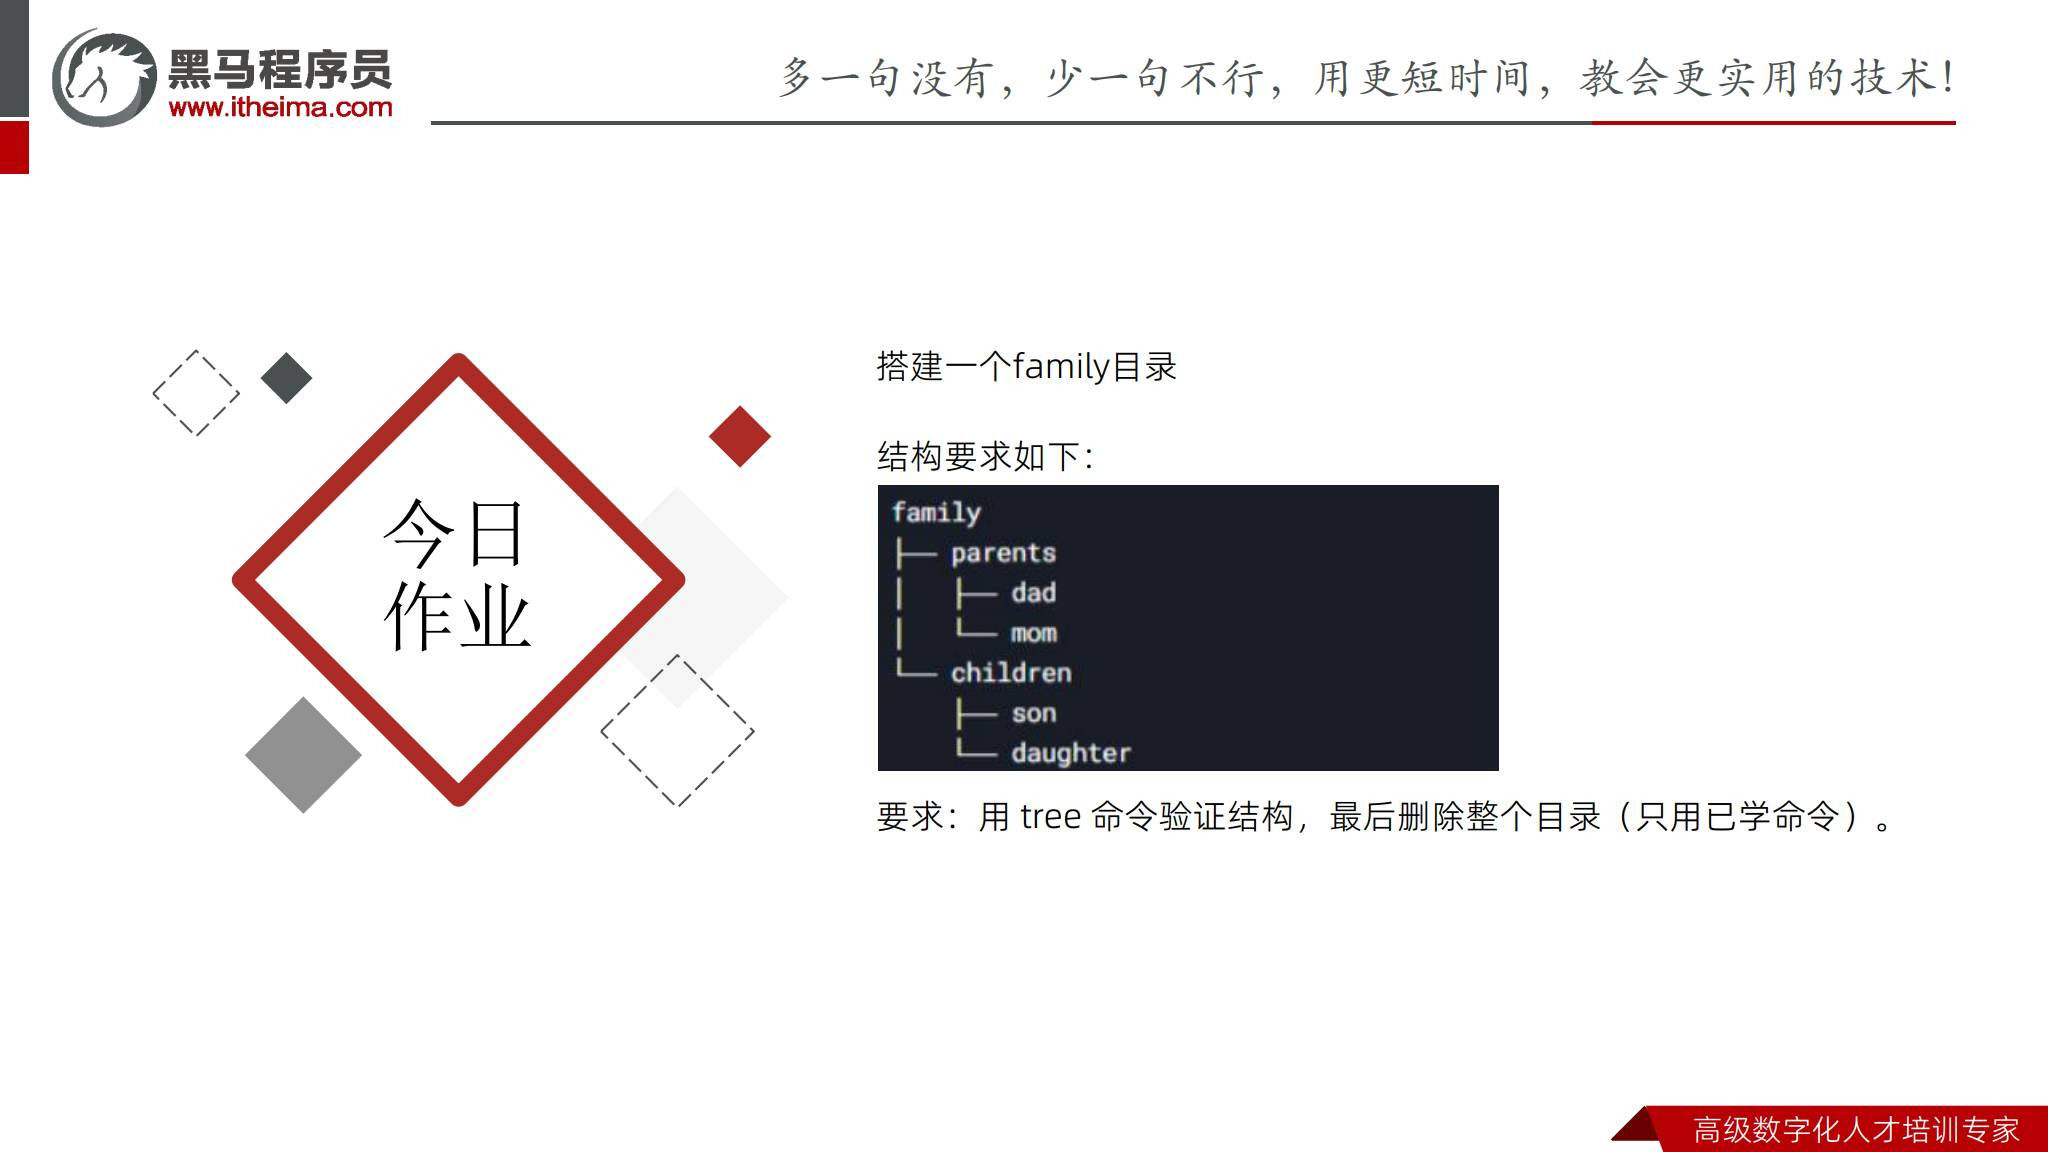

```text
family
├── parents
│   ├── dad
│   └── mom
└── children
    ├── son
    └── daughter
```

**整理补充答案：** 在本节练习目录中创建，使用 `tree` 验证，再只用已学命令删除。

```bash
cd ~/ai-ops-lab/dirs
mkdir -p family/parents/dad family/parents/mom
mkdir -p family/children/son family/children/daughter
tree family
rmdir family/parents/dad family/parents/mom
rmdir family/children/son family/children/daughter
rmdir family/parents family/children
rmdir family
ls -a
```

要点：**删除目录的顺序与创建多级目录的方向相反，先处理最深层。**


## 三、文件操作命令

### 3.1 touch：创建空文件或更新时间

**原课依据：第 16-17、22 页。**

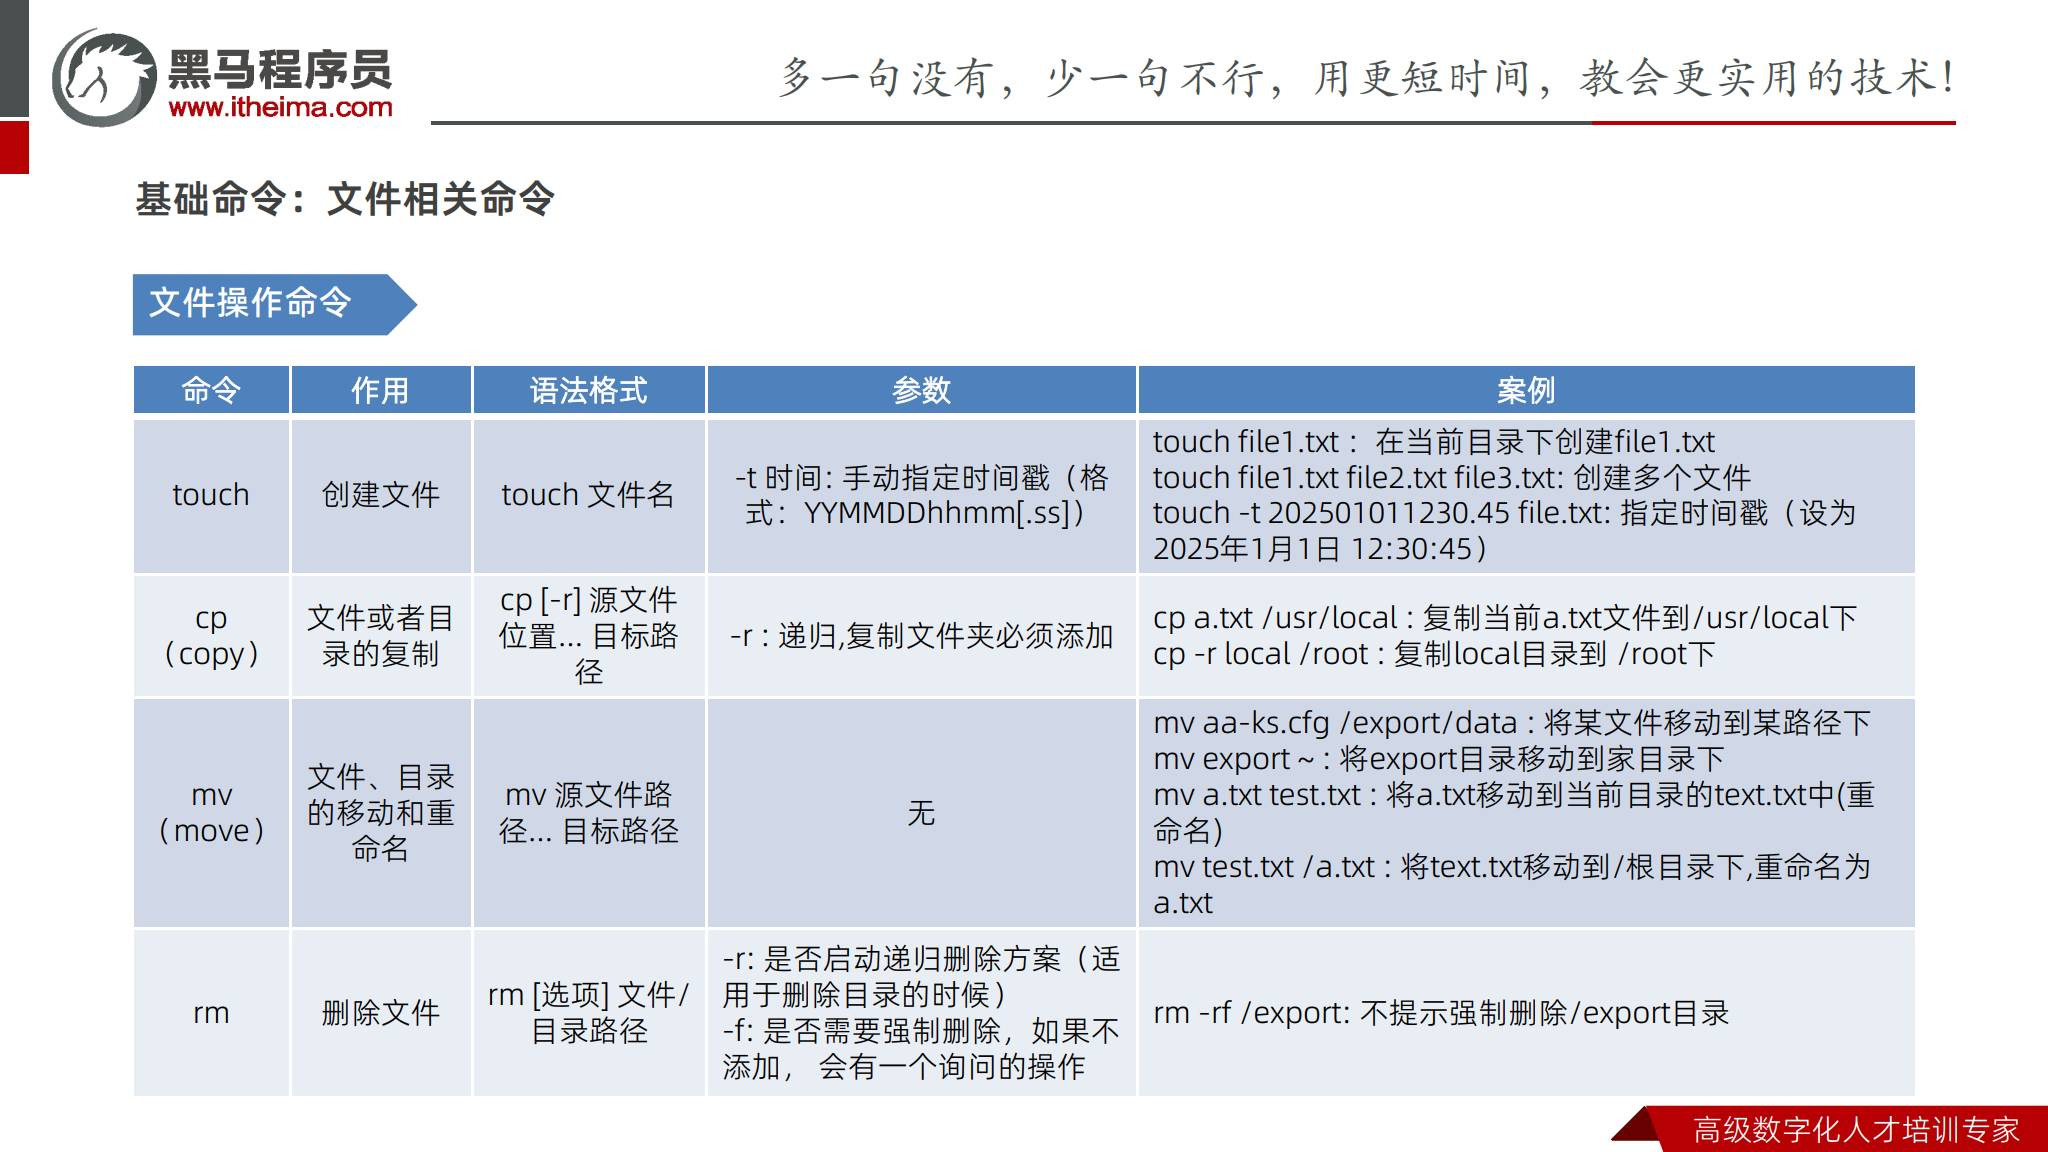

```bash
mkdir -p ~/ai-ops-lab/files
cd ~/ai-ops-lab/files
touch file1.txt
touch file2.txt file3.txt
touch -t 202501011230.45 file1.txt
touch -d "2023-10-01 12:34:56" file2.txt
ls -l
```

| 情况或选项 | 结果 |
| --- | --- |
| 文件不存在 | 创建空文件 |
| 文件已经存在 | 默认更新访问时间和修改时间，原内容保留 |
| `-t [[CC]YY]MMDDhhmm[.ss]` | 按数字格式指定时间，例如 2025-01-01 12:30:45 |
| `-d "时间描述"` | GNU touch 可接受日期字符串及相对时间 |

**整理补充：** 时间戳与文件名中的日期是两件事；把文件命名为 `access_2023-10-01.log` 不会自动把 mtime 设为 2023 年。课件后面的时间筛选练习要用 `touch` 设置或核对时间戳。


### 3.2 cp：复制文件与目录

**原课依据：第 16-17 页。**

```bash
cd ~/ai-ops-lab/files
mkdir -p backup
cp file1.txt copy.txt
cp file1.txt file2.txt backup/
cp -r backup backup_copy
ls -l backup
```

| 命令形式 | 含义 |
| --- | --- |
| `cp 源文件 新文件` | 创建内容副本 |
| `cp 源文件 已有目录/` | 复制到目标目录，通常保留文件名 |
| `cp 文件1 文件2 目标目录/` | 复制多个文件，最后一个参数必须是目录 |
| `cp -r 源目录 目标路径` | 递归复制目录 |

**整理补充：** 目标目录是否已存在会影响最终层级：目标已存在时，源目录通常成为它的子目录。复制前后用 `ls`、`tree` 核对。`cp -i` 可以在覆盖前询问；`cp -p` 可尽量保留时间和权限等属性，日志备份要保留 mtime 时很有用。


### 3.3 mv 与 rm：移动、重命名和删除

**原课依据：第 16-17 页。**

```bash
cd ~/ai-ops-lab/files
mv copy.txt renamed.txt
mv renamed.txt backup/
ls -l backup
rm -i file3.txt
```

| 操作 | 解释 |
| --- | --- |
| `mv a.txt b.txt` | 目标不是已有目录时，把 a.txt 重命名为 b.txt |
| `mv a.txt backup/` | 移到已有目录 |
| `mv 目录 目标路径` | 移动目录，无需像 cp 那样加 `-r` |
| `rm 文件` | 删除文件 |
| `rm -r 目录` | 递归删除目录及其内容 |
| `rm -i 文件` | 明确要求交互确认 |
| `rm -f 文件` | 忽略不存在的文件并取消通常的删除询问，不是“绕过权限” |

课件使用 `rm -rf` 演示强制递归删除。**整理补充：不带 `-f` 并不保证每次都询问**，是否提示还受别名、权限和运行环境影响。`rm` 通常不会把内容移到回收站；练习时先 `pwd`、`ls` 确认对象，再使用明确的练习路径。


## 四、find 文件查找

### 4.1 按名称与类型查找

**原课依据：第 19-20 页。**

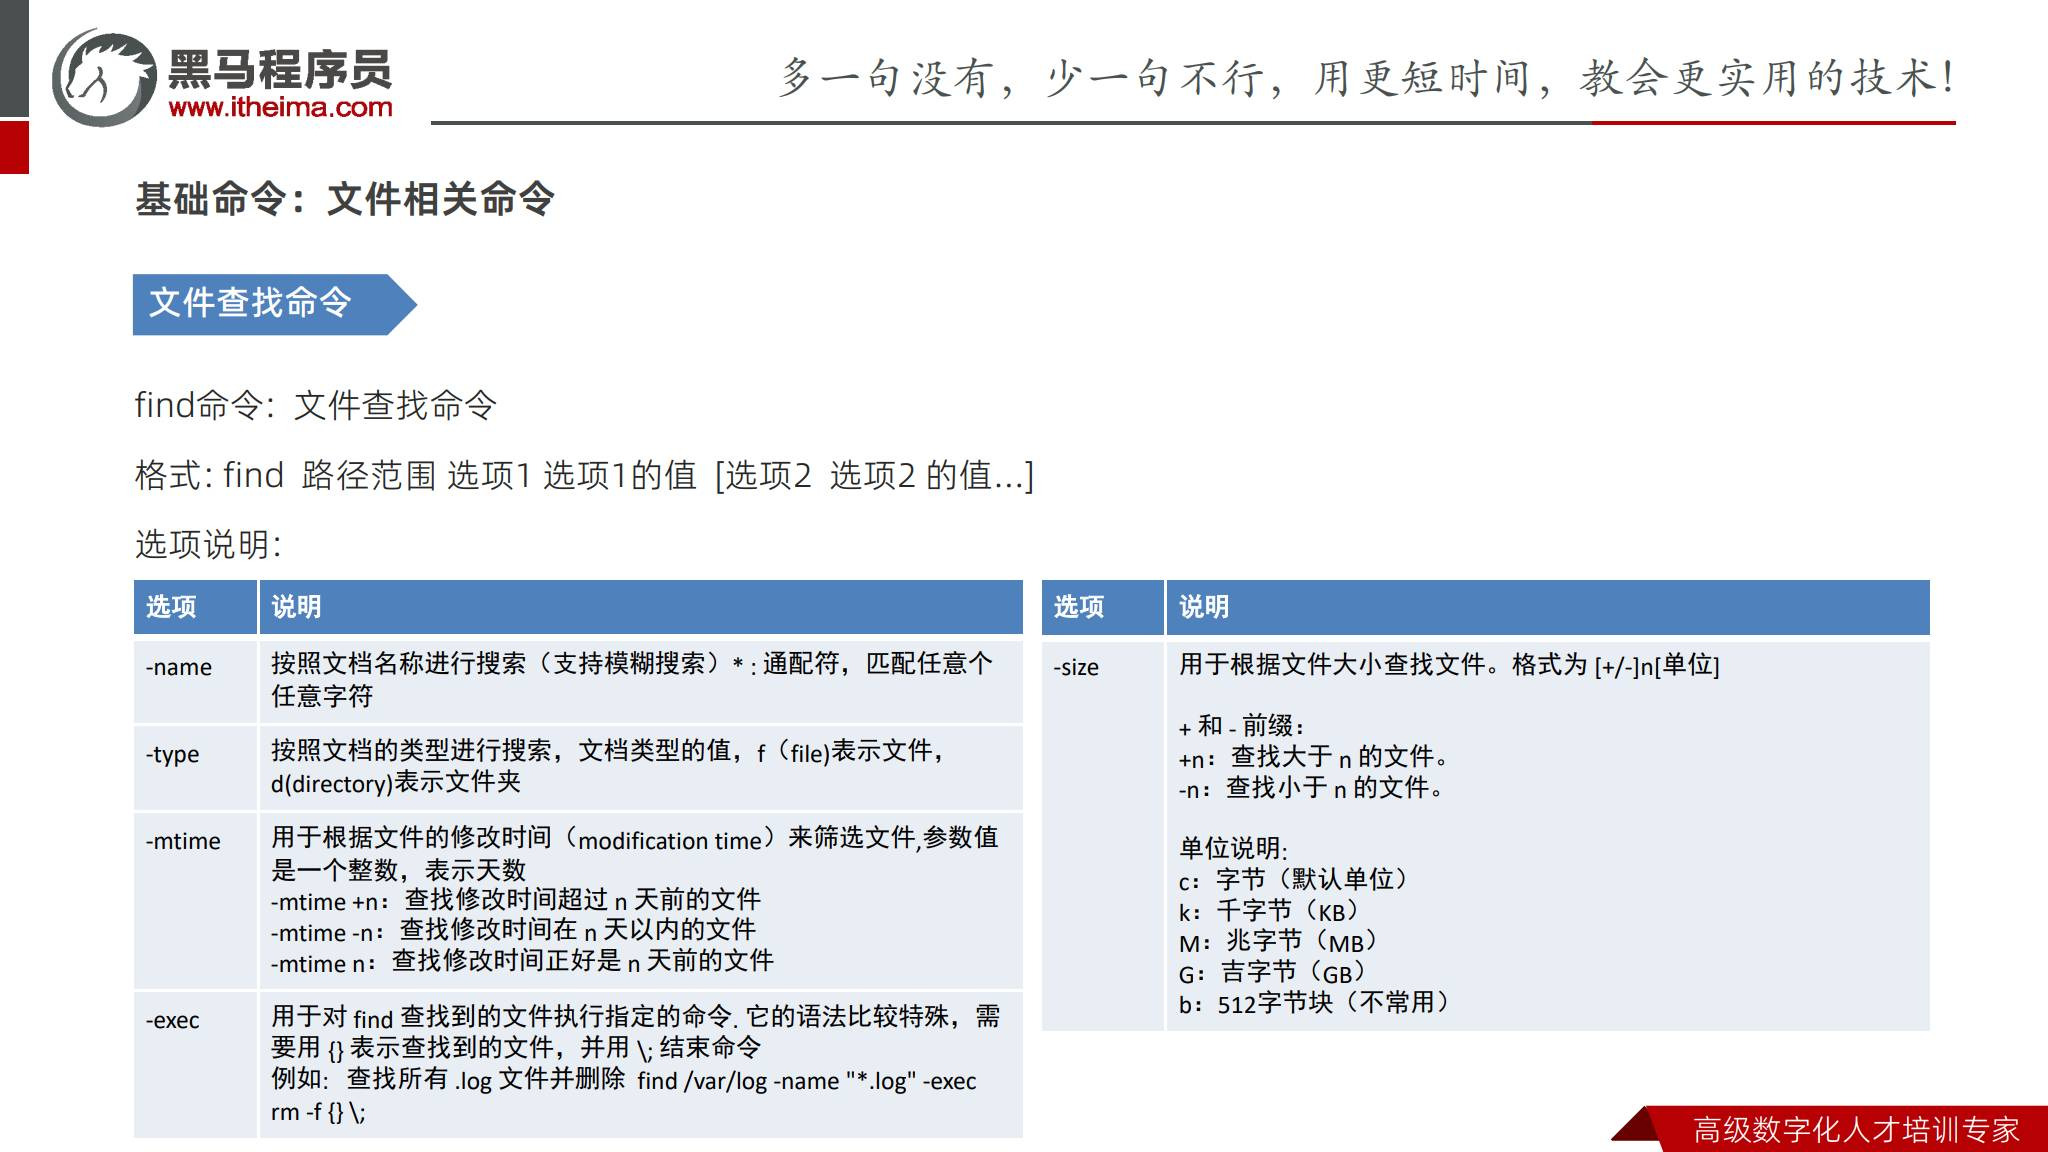

```bash
find ~/ai-ops-lab -type f -name '*.txt'
find ~/ai-ops-lab -type d -name 'backup'
```

| 部分 | 含义 |
| --- | --- |
| `find 路径` | 从指定范围递归查找 |
| `-name '模式'` | 匹配文件或目录的名字；通常区分大小写 |
| `*` | 匹配零个或多个字符 |
| `-type f` | 只匹配普通文件 |
| `-type d` | 只匹配目录 |
| 多个条件并列 | 默认表示条件都要满足 |

**整理补充：** 给 `*.log` 加引号，让模式交给 find，而不是先被当前 Shell 展开。`find` 主要找路径和属性，`grep` 主要找文件中的文本内容。


### 4.2 -mtime：按修改时间筛选

**原课依据：第 19、22-23 页；精确边界为整理补充。** `mtime` 是文件内容最后修改时间，不是文件名日期，也不是创建时间。

GNU find 默认以执行时刻为基准，将经过时间换算为 **完整的 24 小时段，并向下取整**。假设文件不是未来时间：

| 条件 | 实际匹配范围 |
| --- | --- |
| `-mtime 0` | 距今不足 24 小时 |
| `-mtime 1` | 距今至少 24 小时、不足 48 小时 |
| `-mtime -1` | 距今不足 24 小时 |
| `-mtime 3` | 距今至少 72 小时、不足 96 小时 |
| `-mtime +3` | 完整天数大于 3，即距今至少 96 小时 |
| `-mtime +2` | 完整天数大于 2，即距今至少 72 小时 |

```bash
find ~/ai-ops-lab -type f -name '*.log' -mtime -1
find ~/ai-ops-lab -type f -name '*.log' -mtime +2
```

课件用“超过 n 天前”概括 `+n`。实际写清理规则时，要说明是 **至少经过 n×24 小时**、**按完整天数比较**，还是 **按日历日期比较**，这些标准并不相同。

**整理补充：** 如需分钟粒度，可了解 GNU find 的 `-mmin`；如需按当天零点划分，可进一步了解 `-daystart`，本篇案例先统一使用滚动 24 小时段。


### 4.3 -size：按大小查找

**原课依据：第 19-20、23 页；单位纠正为整理补充。**

```bash
find ~/ai-ops-lab -type f -size +100M
find ~/ai-ops-lab -type f -size +104857600c
```

| 写法 | GNU find 中的含义 |
| --- | --- |
| `-size n` | 不写单位时默认以 512 字节块计数 |
| `-size nc` | 以字节计数 |
| `-size nk` | 以 1024 字节单位计数 |
| `-size nM` | 以 1024² 字节单位计数 |
| `-size nG` | 以 1024³ 字节单位计数 |
| `+n` / `-n` / `n` | 大于 / 小于 / 等于该单位计数 |

课件把 `c` 标为“默认单位”，这里纠正为：**`c` 是字节单位，省略单位的默认值是 `b`，即 512 字节块。**

**整理补充：** 除字节外，大小会按指定单位向上取整再比较。例如 `-size 1M` 可匹配大于 0 且不超过 1 MiB 的文件，并非只匹配恰好 1 MiB。要求严格字节边界时写 `c`；`+100M` 对应大于 100 MiB，十进制 100 MB 则可写 `+100000000c`。


### 4.4 -exec：对查到的路径执行命令

**原课依据：第 19-20 页。**

```bash
find ~/ai-ops-lab -type f -name '*.txt' -exec ls -lh -- {} \;
```

| 片段 | 含义 |
| --- | --- |
| `-exec` | 指定对匹配结果执行的命令 |
| `{}` | 在这种写法中，替换为当前匹配到的路径 |
| `\;` | 结束 exec 命令；反斜杠使分号不被 Shell 当作命令分隔符 |
| `--` | 整理补充：告诉支持该写法的命令，后面是操作对象，不再解析为选项 |

课件用查找并删除日志演示 `-exec`。整理成练习时，先执行同条件的查找，核对列表后再执行删除：

```bash
find ~/ai-ops-lab -type f -name '*.log' -mtime +30 -print
# 仅针对上面已确认的练习文件
find ~/ai-ops-lab -type f -name '*.log' -mtime +30 -exec rm -i -- {} \;
```

**整理补充：** `{} \;` 通常逐个结果执行；还有 `{} +` 的批量形式。不要把 `-exec` 误认为“只显示命令”，它会真正运行指定操作。


### 4.5 原课案例：日志文件管理与备份

**原课依据：第 22 页。** 原题在 `/var/log/app` 创建 6 个日期不同的日志，将 3 天前的日志复制到 `/backup/old_logs`，删除 5 天前的日志。

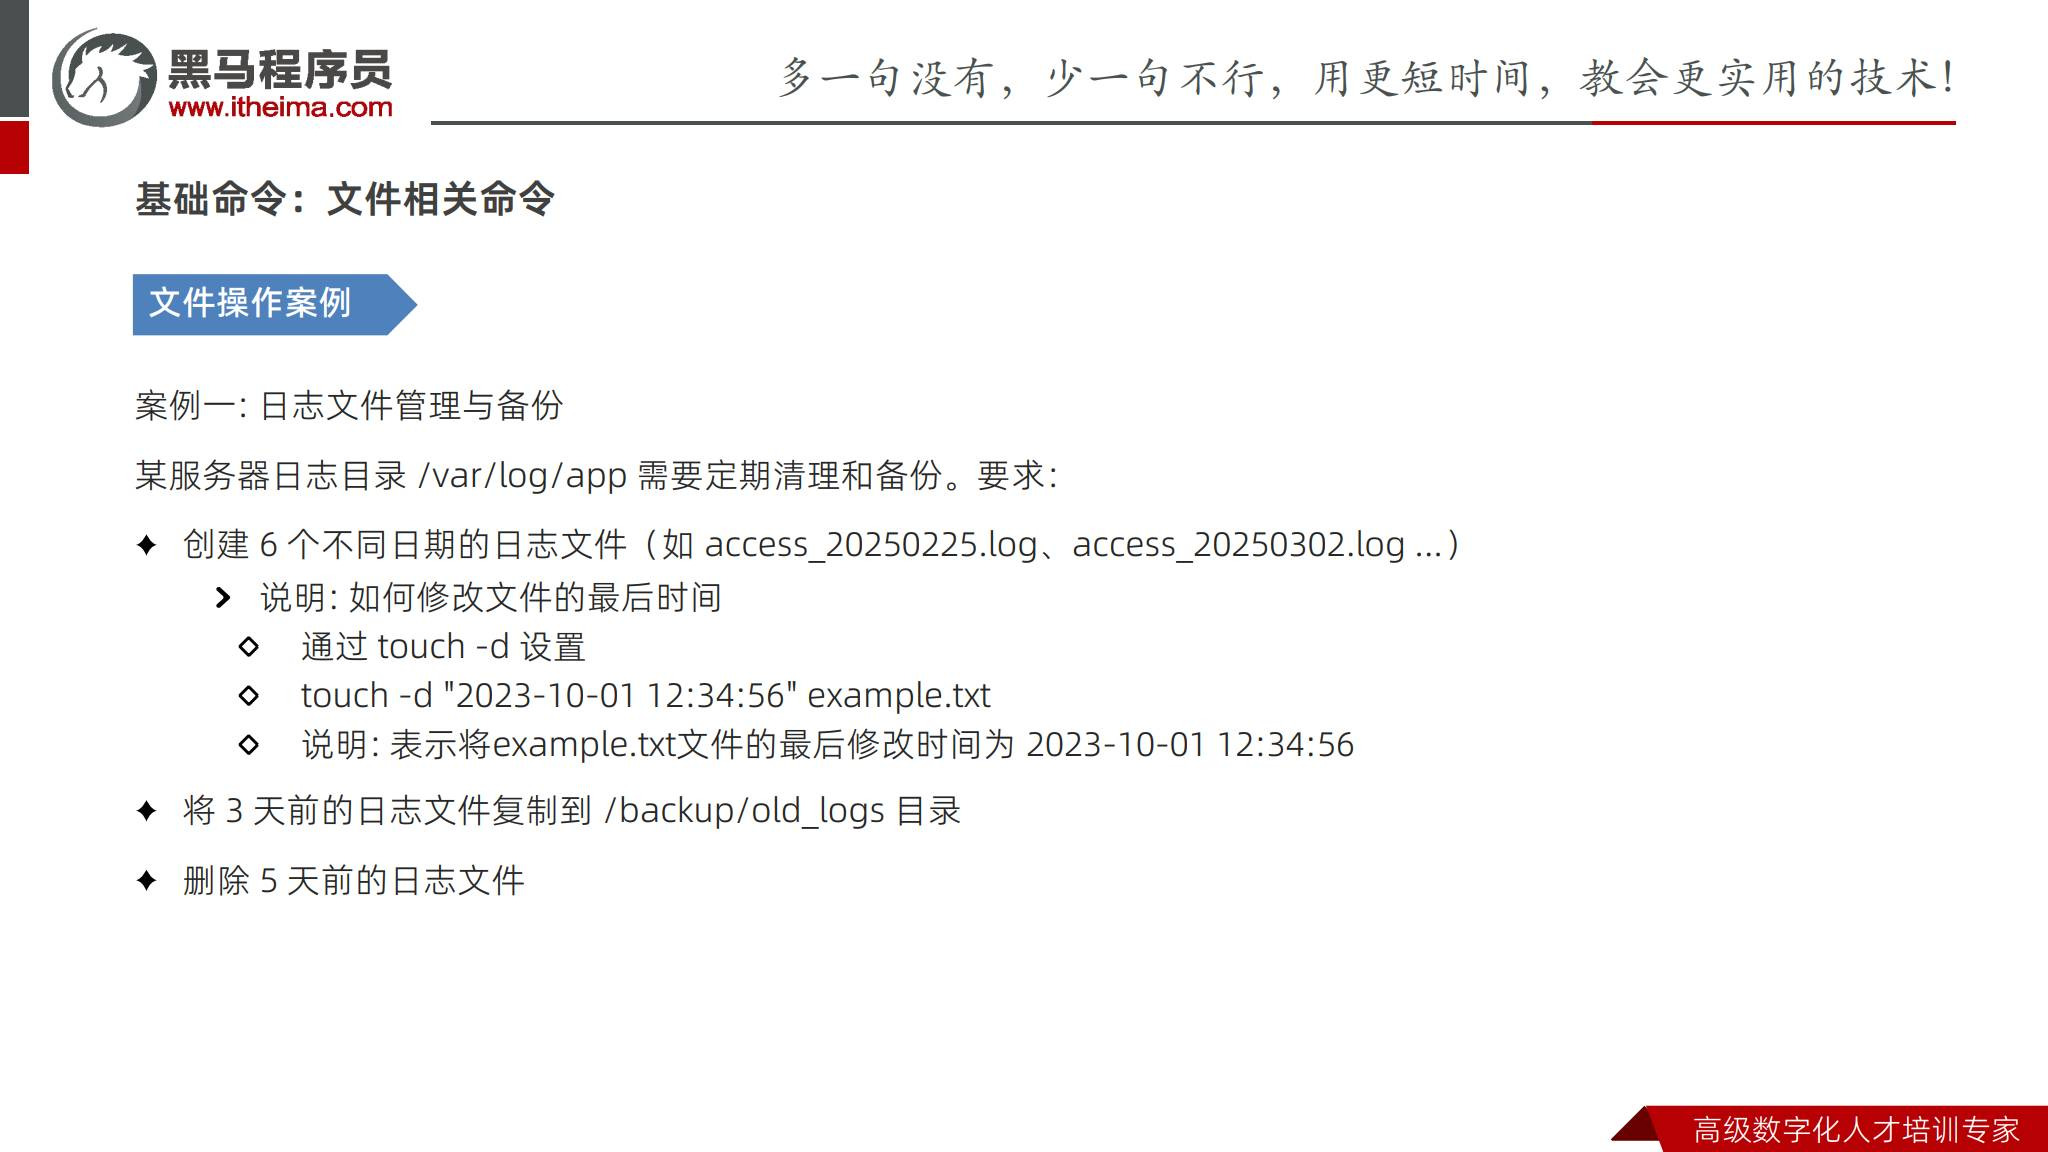

**整理补充答案：** 用个人练习目录复现；本例把规则明确为“至少 3×24 小时前修改的日志备份，至少 5×24 小时前修改的日志删除”。日期与时间戳分开设置，避免照搬历史日期导致全部匹配。

```bash
mkdir -p ~/ai-ops-lab/log-case/app ~/ai-ops-lab/log-case/old_logs
cd ~/ai-ops-lab/log-case/app
touch access_today.log access_1day.log access_3days.log
touch access_4days.log access_5days.log access_6days.log
touch -d '1 day ago' access_1day.log
touch -d '3 days ago' access_3days.log
touch -d '4 days ago' access_4days.log
touch -d '5 days ago' access_5days.log
touch -d '6 days ago' access_6days.log

find . -type f -name 'access_*.log' -mtime +2 -print
find . -type f -name 'access_*.log' -mtime +2 -exec cp -p -- {} ../old_logs/ \;
ls -l ../old_logs

find . -type f -name 'access_*.log' -mtime +4 -print
find . -type f -name 'access_*.log' -mtime +4 -exec rm -i -- {} \;
ls -l .
```

首次练习并确认删除时，预计备份 3、4、5、6 天前的 **4 个**日志，源目录保留今天、1 天前、3 天前、4 天前的 **4 个**日志。文件大小为 0，练习的是路径和时间条件；实际备份后还应核对内容。


### 4.6 原课作业一：清理临时文件

**原课依据：第 23 页。** 查找 `/tmp/userdata` 中 24 小时内修改过的 `tmp_*` 文件，移动到 `/tmp/recent`；删除超过 30 天未修改的同类文件。

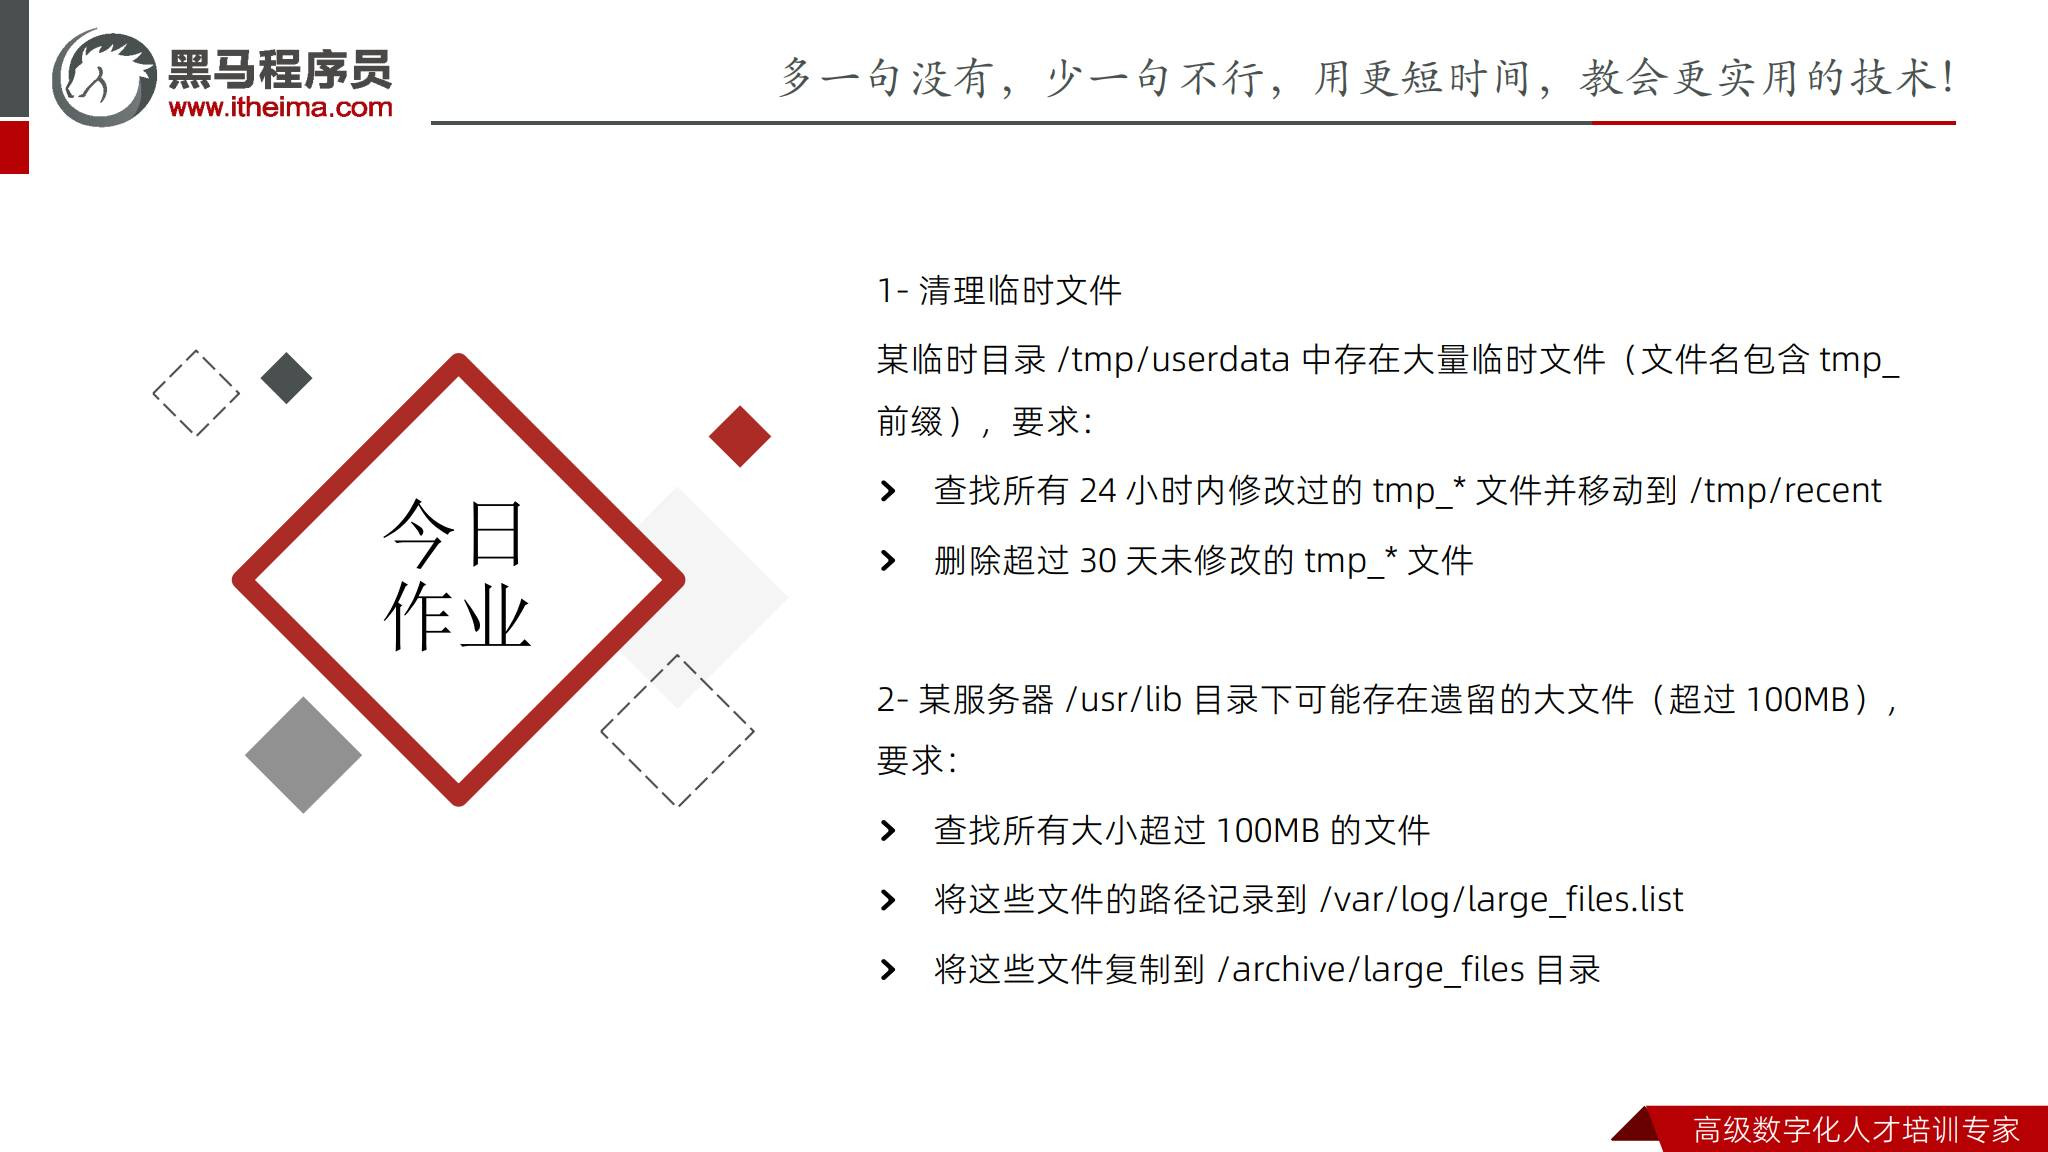

**整理补充答案：** 在练习目录创建 2 小时、10 天和 31 天前的样本。保留原题的文件筛选条件，路径改为个人目录。

```bash
mkdir -p ~/ai-ops-lab/temp-case/userdata ~/ai-ops-lab/temp-case/recent
cd ~/ai-ops-lab/temp-case
touch userdata/tmp_recent userdata/tmp_middle userdata/tmp_old
touch -d '2 hours ago' userdata/tmp_recent
touch -d '10 days ago' userdata/tmp_middle
touch -d '31 days ago' userdata/tmp_old

find userdata -type f -name 'tmp_*' -mtime -1 -print
find userdata -type f -name 'tmp_*' -mtime -1 -exec mv -- {} recent/ \;
find userdata -type f -name 'tmp_*' -mtime +30 -print
find userdata -type f -name 'tmp_*' -mtime +30 -exec rm -i -- {} \;
ls -l userdata recent
```

确认删除后，recent 中应有 tmp_recent，userdata 中只剩 tmp_middle。这里的 `+30` 表示完整天数大于 30，即至少 31×24 小时；若规则改为“至少 30×24 小时”，应使用 `+29`。


### 4.7 原课作业二：查找、记录与复制大文件

**原课依据：第 23 页。** 从 `/usr/lib` 找出超过 100MB 的文件，把路径写入 `/var/log/large_files.list`，复制到 `/archive/large_files`。

**整理补充答案：** 下面保留 `/usr/lib` 的读取范围，将输出写到家目录练习区。大小标准采用 GNU find 的 100 MiB；输出重定向 `>` 在第六节解释。

```bash
mkdir -p ~/ai-ops-lab/large-case/archive
find /usr/lib -type f -size +100M -print > ~/ai-ops-lab/large-case/large_files.list
cat ~/ai-ops-lab/large-case/large_files.list
```

确认列表与目标空间后，可复制并保留来源目录层级：

```bash
find /usr/lib -type f -size +100M \
  -exec cp --parents -- {} ~/ai-ops-lab/large-case/archive/ \;
tree -L 4 ~/ai-ops-lab/large-case/archive
```

**整理补充：** `cp --parents` 是 GNU cp 功能，可避免不同来源目录的同名文件都复制到同一层而覆盖。若一定要照原题写入 `/var/log` 和 `/archive`，需事先确认权限、目标目录与空间。实际机器可能没有匹配项，或大文件位于 `/usr/lib64`，不能为了得到结果任意修改系统文件。

查找报出的权限错误属于标准错误输出，`>` 默认只记录正常结果。复制后用 `ls -lh`、文件内容或校验值核对；列表有路径不代表复制一定成功。


## 五、vi/vim 编辑文件

### 5.1 打开文件与编辑器准备

**原课依据：第 25-26 页。** `vi` 是传统文本编辑器，`vim` 是 Vi IMproved，常见增强功能有语法高亮、多级撤销、代码折叠与插件支持。

```bash
vim ~/ai-ops-lab/files/file1.txt
vim +10 ~/ai-ops-lab/files/file1.txt
```

第二条表示打开后定位到第 10 行。文件不存在时可进入新缓冲区，真正写入磁盘发生在保存时；父目录必须存在且有写入条件。

课件给出 `dnf install -y vim`。**整理补充：** 在 CentOS Stream 9 中，需要安装时可由管理员执行 `sudo dnf install vim`；`-y` 是自动确认，不是所有系统的通用安装方式。`vi` 是否链接到 Vim、启动的是哪种兼容设置，要根据实际软件包判断，可查看 `command -v vi` 和 `vi --version`，不应仅凭“RHEL 9”断言。


### 5.2 三种模式与切换

**原课依据：第 27、29、31 页。** 本课用三种模式建立入门模型：命令模式、插入模式、末行模式。

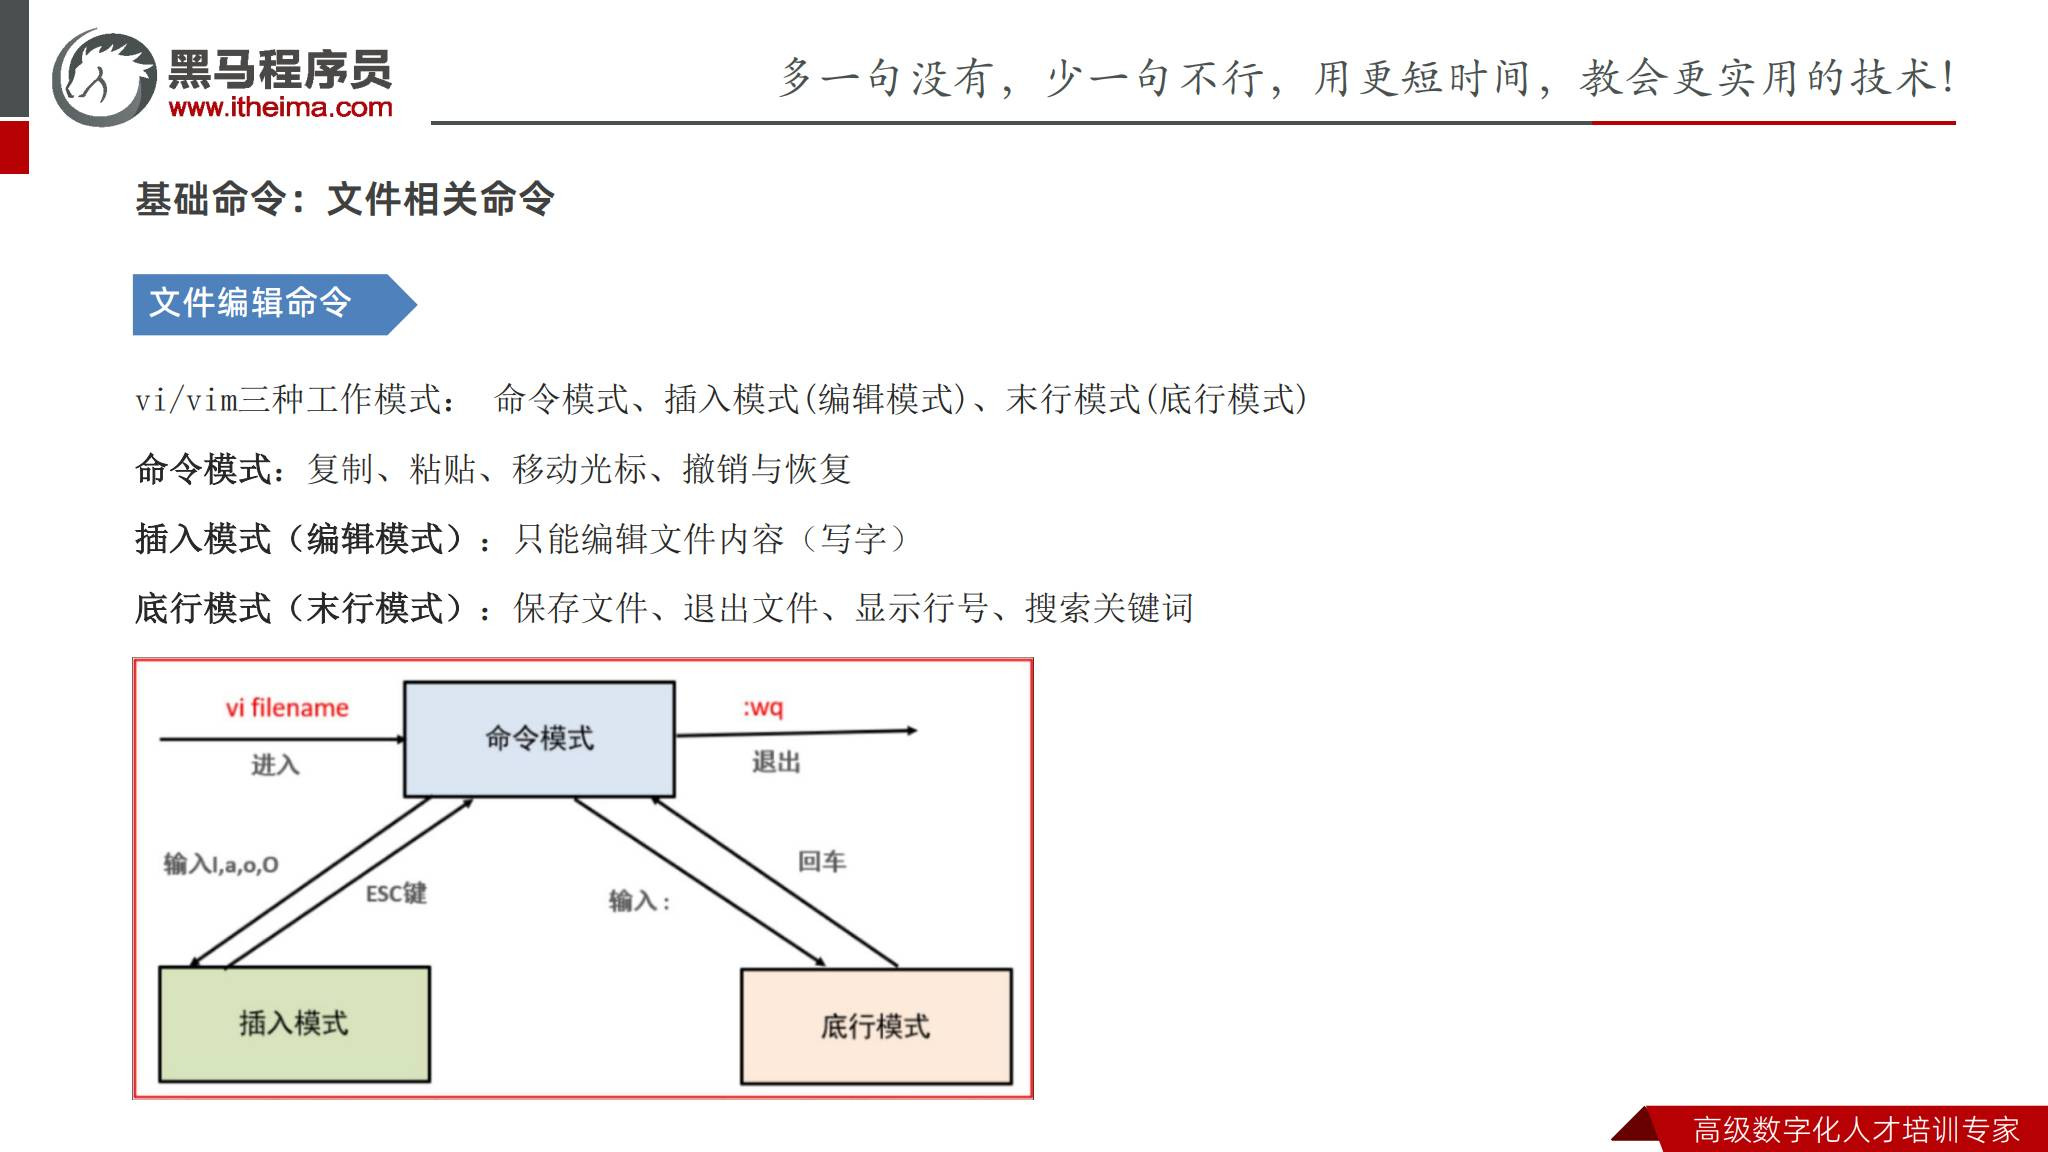

```text
启动 vim
   ↓
命令模式（Normal） ── i / a / o / O ──→ 插入模式
   ↑                                   │
   └────────────── Esc ────────────────┘

命令模式 ── : ──→ 末行命令输入 ── Enter ──→ 执行命令
    ↑                   │
    └────── Esc ────────┘
```

| 模式 | 主要用途 | 如何判断与操作 |
| --- | --- | --- |
| 命令模式 | 光标移动、复制、删除、撤销 | 字母按键执行编辑命令 |
| 插入模式 | 输入或修改文字 | 一般显示 INSERT 等状态提示；按 Esc 返回 |
| 末行模式 | 输入保存、退出、设置等命令 | 从命令模式按 `:`，底部出现命令输入行 |

**整理补充：** Vim 还有可视模式等，课件的“三种”是入门简化。状态提示可以被设置关闭，不能只因左下角没有文字就认定模式；拿不准时先按 Esc，再输入所需命令。


### 5.3 命令模式与进入插入模式的按键

**原课依据：第 28-29 页。**

| 按键 | 功能 |
| --- | --- |
| `i` | 在光标前进入插入模式 |
| `a` | 在光标后进入插入模式 |
| `o` | 在当前行下方新建一行并进入插入模式 |
| `O` | 在当前行上方新建一行并进入插入模式 |
| `dd` / `3dd` | 删除当前行 / 从当前行开始删除 3 行，内容通常进入寄存器 |
| `yy` / `3yy` | 复制当前行 / 从当前行开始复制 3 行 |
| `p` | 粘贴；对于整行内容通常放在当前行之后 |
| `u` | 撤销 |
| `Ctrl+R` | 重做被撤销的修改 |
| `gg` | 到文件开头 |
| `G` | 到文件末尾 |

数字是重复次数。例如先按 `3` 再按 `y`、`y`，不输入空格。`o` 和 `O` 执行后已经进入插入模式，接着可以直接打字。

**整理补充：** `dd` 只改变缓冲区，保存后才反映到文件；误删可先按 Esc，再按 `u`。编辑器内的 `p` 不等同于终端或 Windows 的粘贴快捷键。


### 5.4 保存、退出、行号、搜索与替换

**原课依据：第 30 页。**

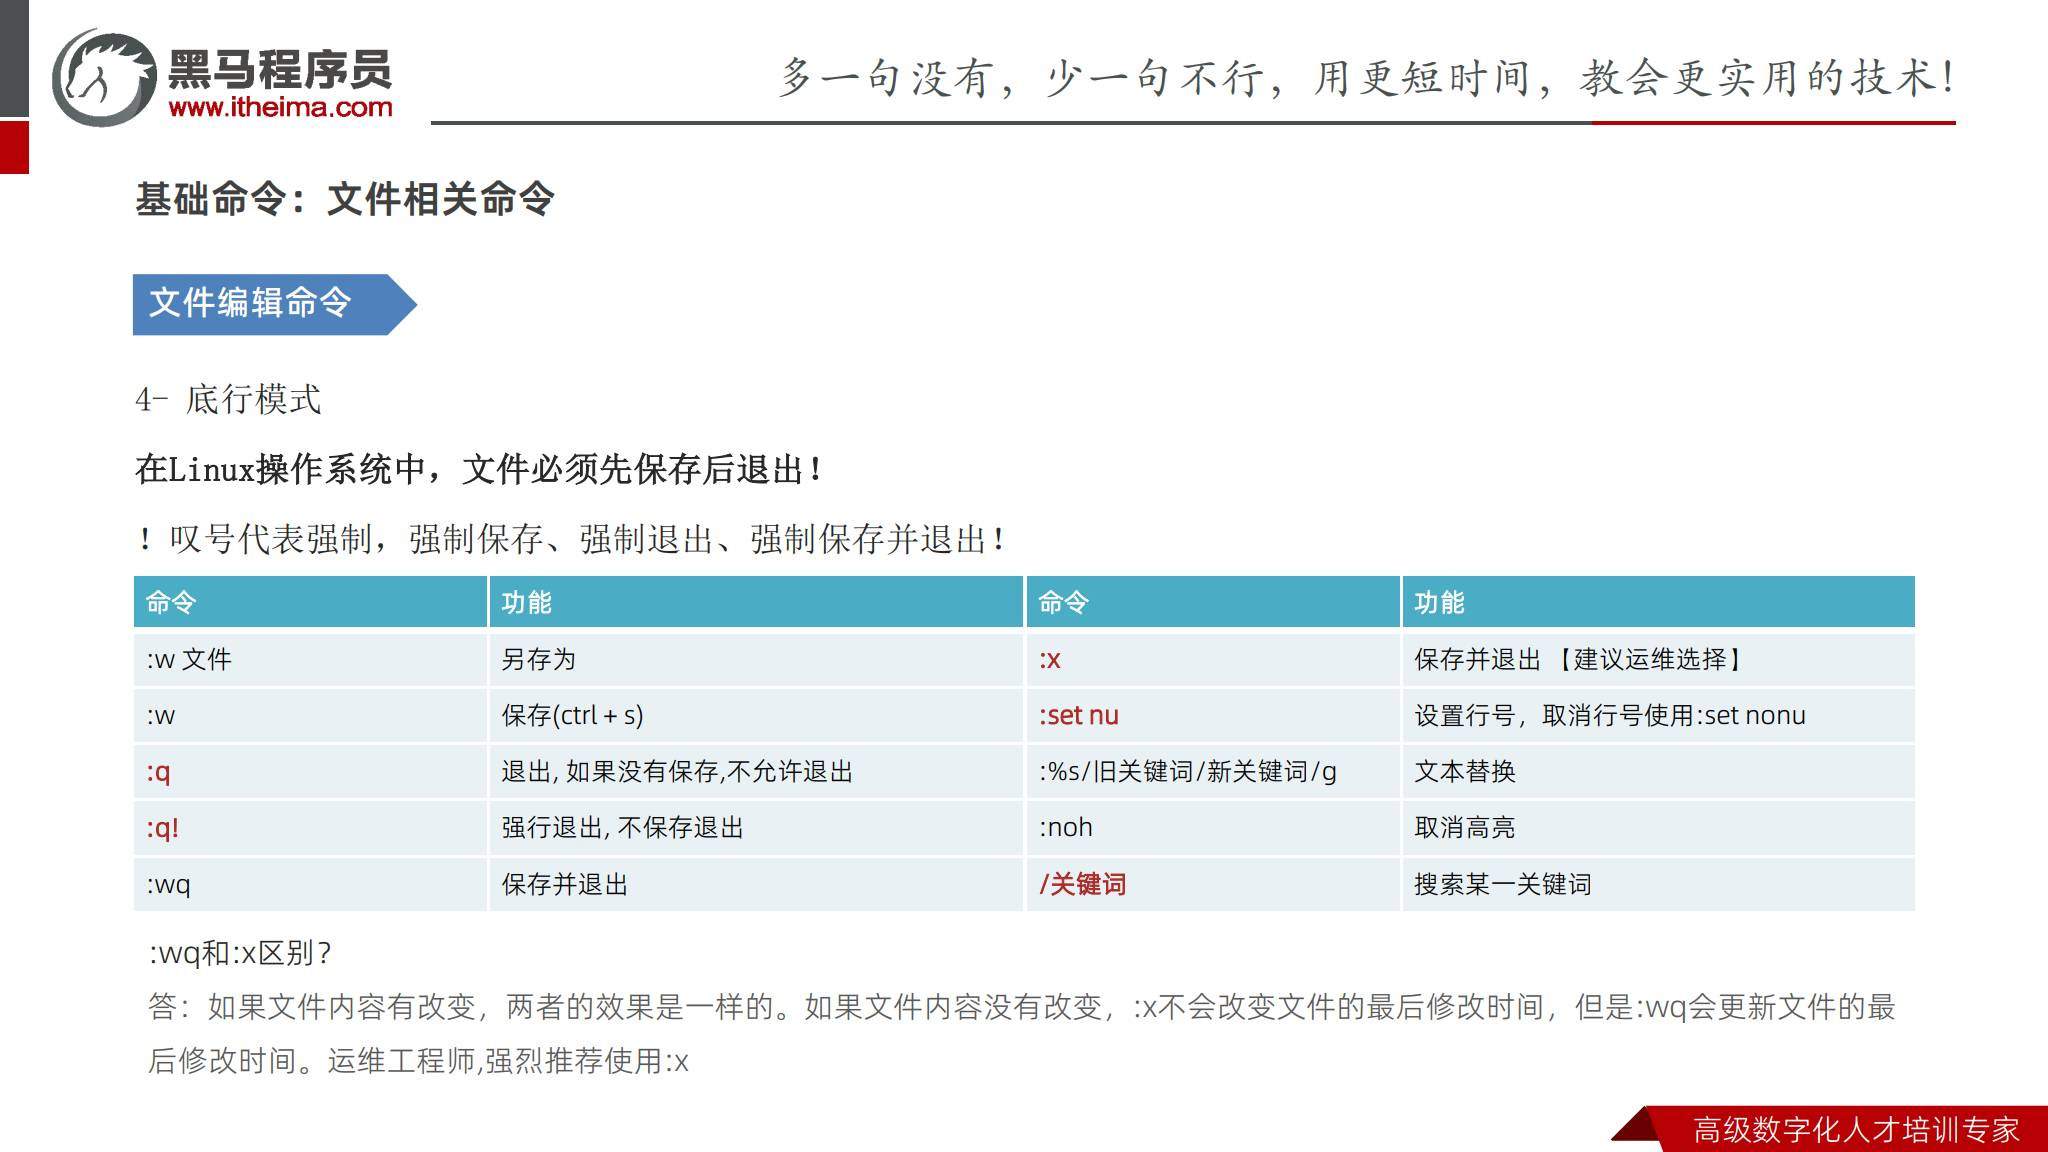

| 命令 | 含义 |
| --- | --- |
| `:w` | 写入当前文件，继续编辑 |
| `:w 新路径` | 把当前内容写到指定路径；与“切换当前文件名”不完全等同 |
| `:q` | 退出；有未保存改动时通常拒绝 |
| `:q!` | 放弃当前未保存改动并退出 |
| `:wq` | 写入后退出 |
| `:x` | 有修改时写入，然后退出 |
| `:set nu` / `:set nonu` | 显示 / 隐藏行号 |
| `/关键词`，再 Enter | 向后搜索；`n` 下一处、`N` 上一处 |
| `:noh` | 取消本轮搜索高亮 |
| `:%s/旧词/新词/g` | 对所有行执行替换，每行替换全部匹配 |

**整理补充：** `/关键词` 是从命令模式开始的搜索输入，不需要先输入冒号。`g` 指每行的全部匹配，不是单独决定“整个文件”；`%` 才代表所有行。可用 `:%s/旧词/新词/gc` 逐项确认。

课件推荐 `:x`：内容没有改变时，`:x` 通常不重新写文件，`:wq` 则执行写入，可能更新 mtime。`!` 的行为取决于命令，**不代表自动获得管理员权限**；只读或权限不足要解决权限原因。Vim 中不必使用 Ctrl+S 保存，在某些终端它会暂停输出，可用 Ctrl+Q 恢复。


### 5.5 整理补充练习：编辑一个应用配置

下面从新的练习文件开始，熟悉“打开 → 修改 → 保存 → 验证”。

```bash
mkdir -p ~/ai-ops-lab/vim-case
vim ~/ai-ops-lab/vim-case/app.conf
```

操作步骤：

1. 按 `i`，输入以下 3 行文本。
2. 按 Esc，输入 `:set nu` 并回车，查看行号。
3. 输入 `/8080` 并回车，定位端口；输入 `:%s/8080/9090/g` 并回车。
4. 按 Esc，输入 `:x` 并回车。
5. 返回终端后用 `cat` 检查，PORT 应为 9090。

```ini
APP_NAME=demo
PORT=8080
LOG_LEVEL=INFO
```

```bash
cat ~/ai-ops-lab/vim-case/app.conf
```

练习的是普通文本编辑，不代表真实应用一定采用这些配置项。实际修改服务配置还要符合软件语法，并按该软件方式检查和生效。


### 5.6 E325 与 .swp：编辑异常及恢复

**原课依据：第 33 页；处理条件为整理补充。**

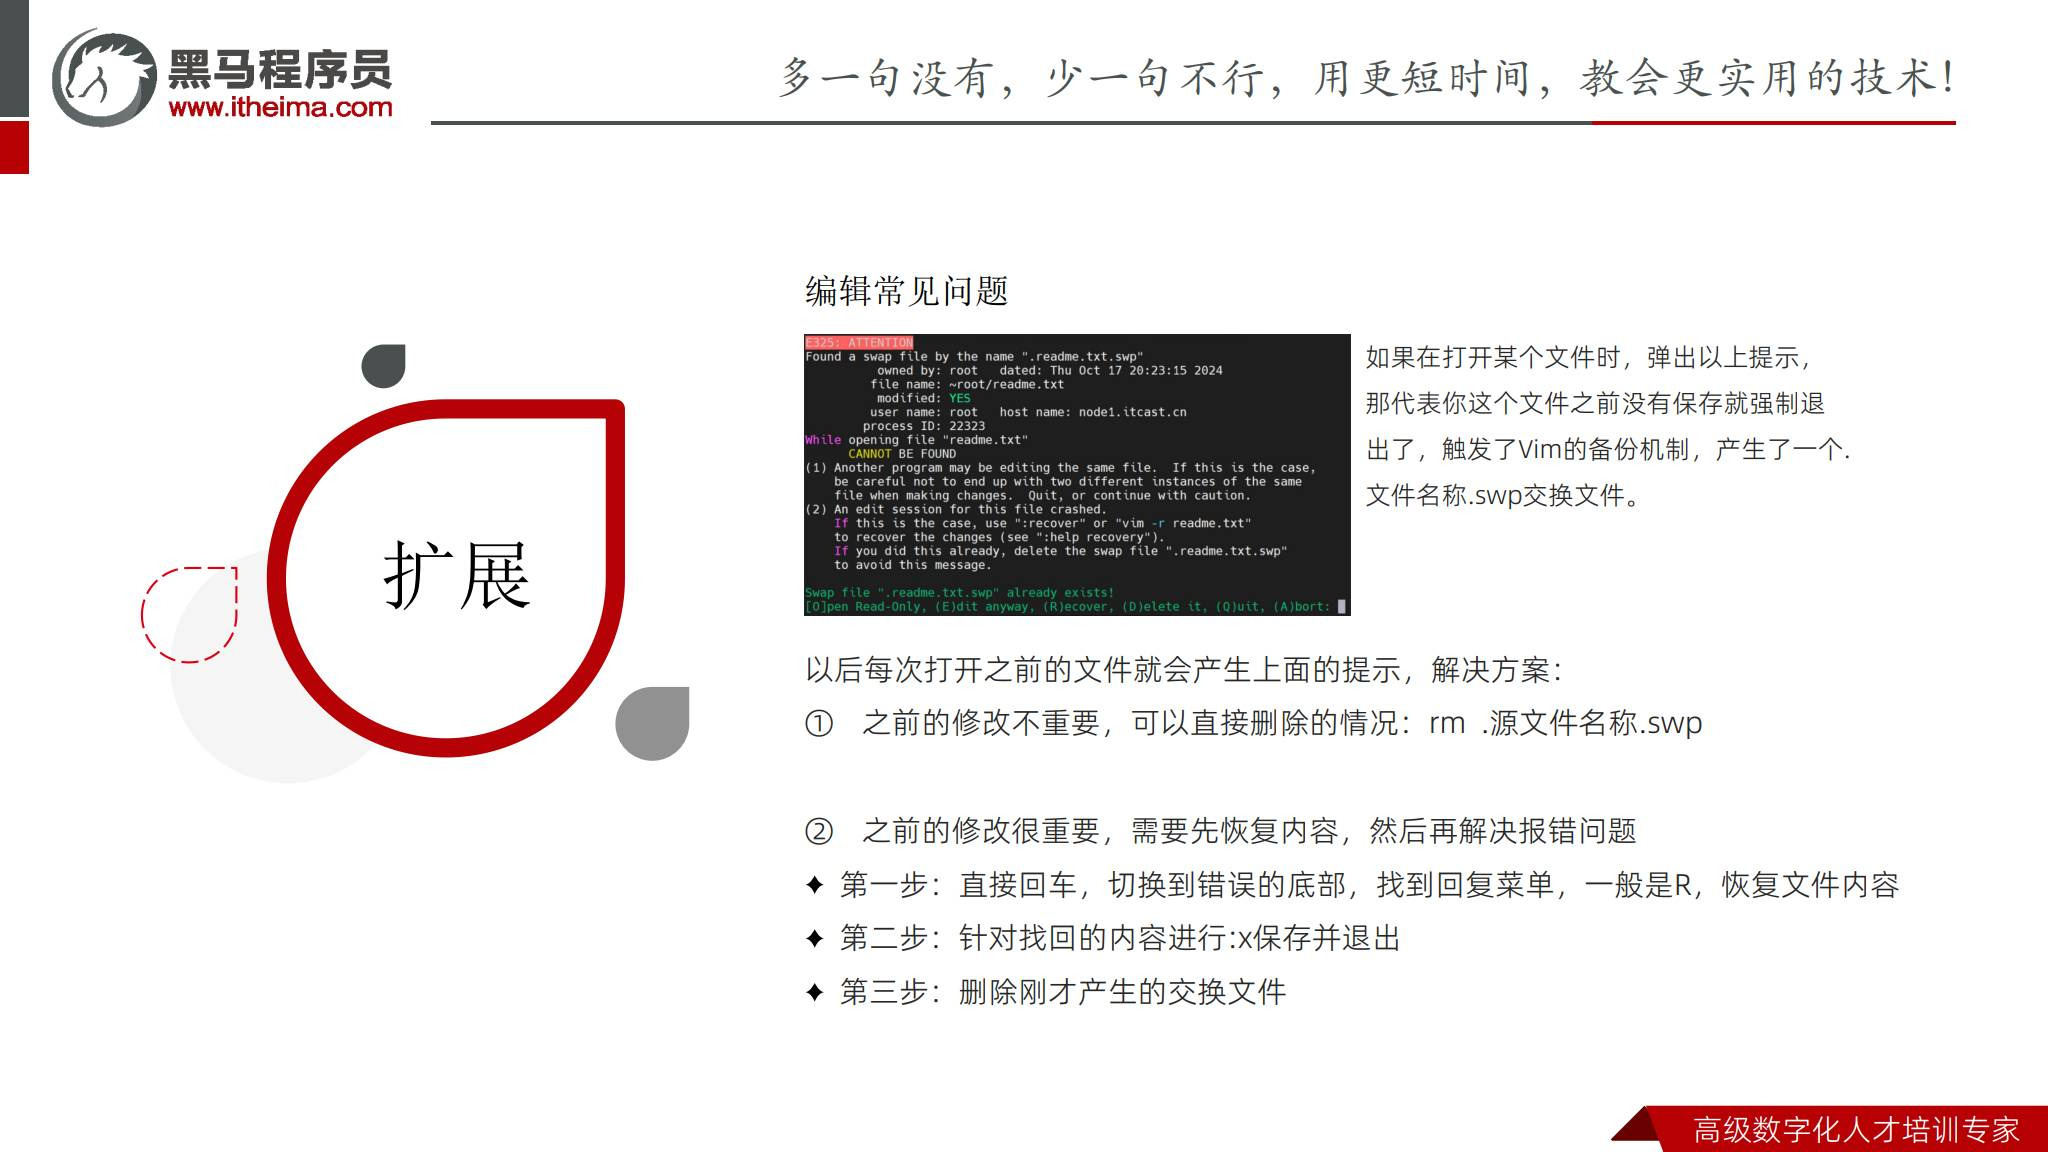

Vim 的交换文件用于辅助恢复，常见名称类似 `.readme.txt.swp`。出现 E325 提示，可能是上次会话异常结束留下交换文件，**也可能另一个编辑器仍在编辑同一文件**。

| 看到的情况 | 应先做的判断 |
| --- | --- |
| 提示进程仍在运行 | 确认是否有另一个有效编辑会话，避免并发覆盖 |
| 上次连接断开或编辑器退出异常 | 考虑恢复未保存内容 |
| 已确认交换文件过期，内容不再需要 | 核对准确位置后再删除指定交换文件 |

恢复步骤可按提示选择 `R`，或在终端使用：

```bash
vim -r ~/ai-ops-lab/vim-case/app.conf
```

检查恢复的内容，必要时先写到新文件，例如在 Vim 中执行 `:w app.conf.recovered`。比较原文件和恢复文件，确认保存成功，并关闭相关编辑会话后，才处理已确认的旧交换文件。

**整理补充：** 交换文件可能不在源文件旁，后缀也不一定正好是 `.swp`，以报错显示的路径为准。不能一见 E325 就批量删除交换文件；正常的 `:q!` 是主动丢弃改动退出，通常会清理当前交换文件，不等同于异常崩溃。


## 六、查看、筛选与统计文件

### 6.1 cat、more 与 less

**原课依据：第 35、38 页。**

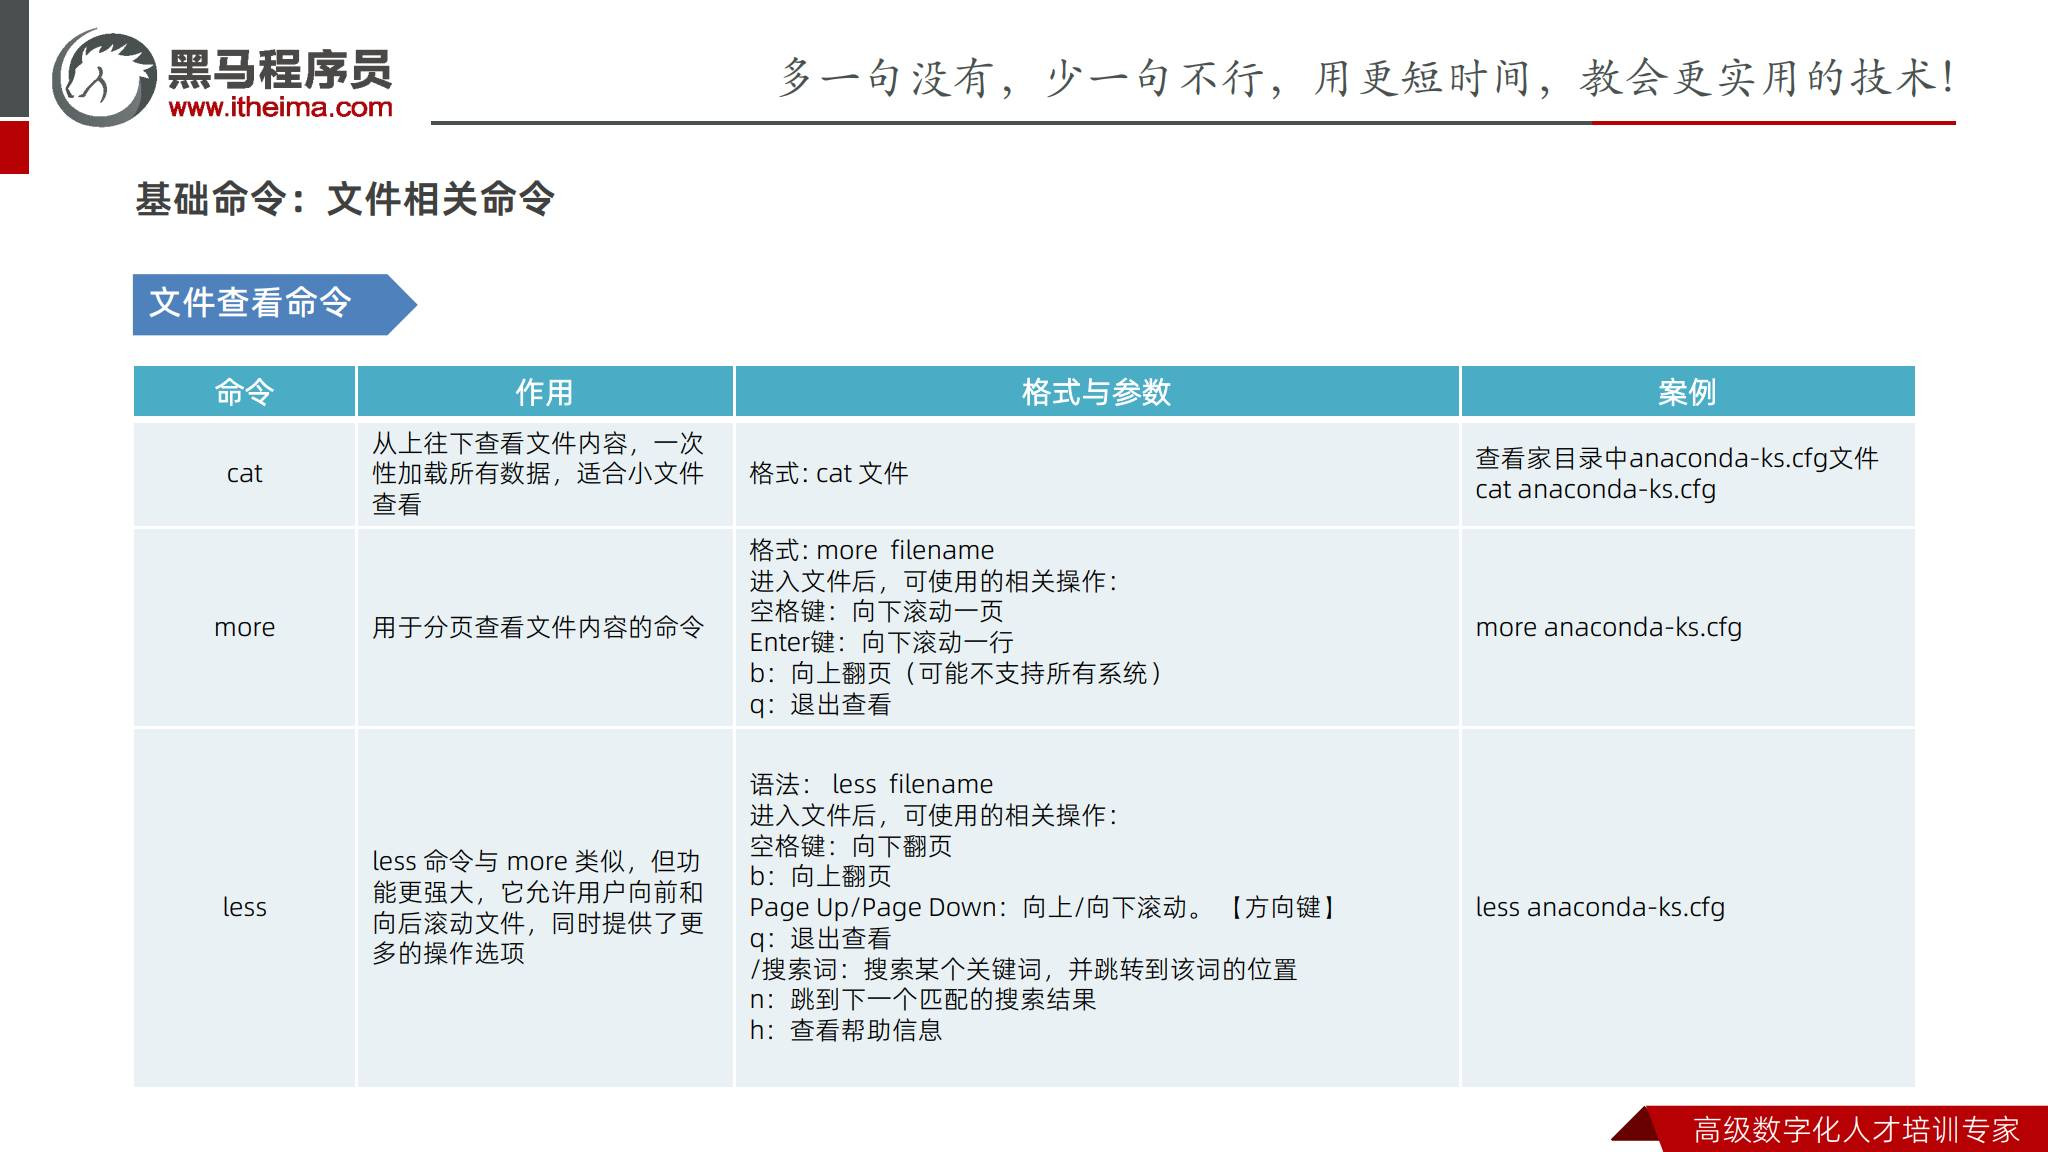

| 命令 | 适合什么场景 |
| --- | --- |
| `cat 文件` | 把内容连续输出，适合较小的文本文件 |
| `cat a.txt b.txt` | 按参数顺序连续输出两个文件 |
| `more 文件` | 分页阅读，主要向下查看 |
| `less 文件` | 前后翻页、搜索，更适合较大文本 |

| 阅读操作 | more | less |
| --- | --- | --- |
| 向下翻页 | 空格 | 空格 |
| 向下一行 | Enter | Enter / 方向键 |
| 向上翻页 | 部分环境支持 `b` | `b` / Page Up |
| 搜索 | 依实现而定 | `/关键词`，Enter，`n` 下一处 |
| 退出 | `q` | `q` |
| 帮助 | 依实现而定 | `h` |

**整理补充：** 课件把 cat 描述为“一次加载所有数据”，更准确地说它会连续读取并输出，并不必然把整个文件一次载入内存。大文件用 cat 容易刷屏，通常选 less；二进制文件也不适合直接当文本输出。


### 6.2 head 与 tail：开头、末尾及持续查看

**原课依据：第 36-38 页。**

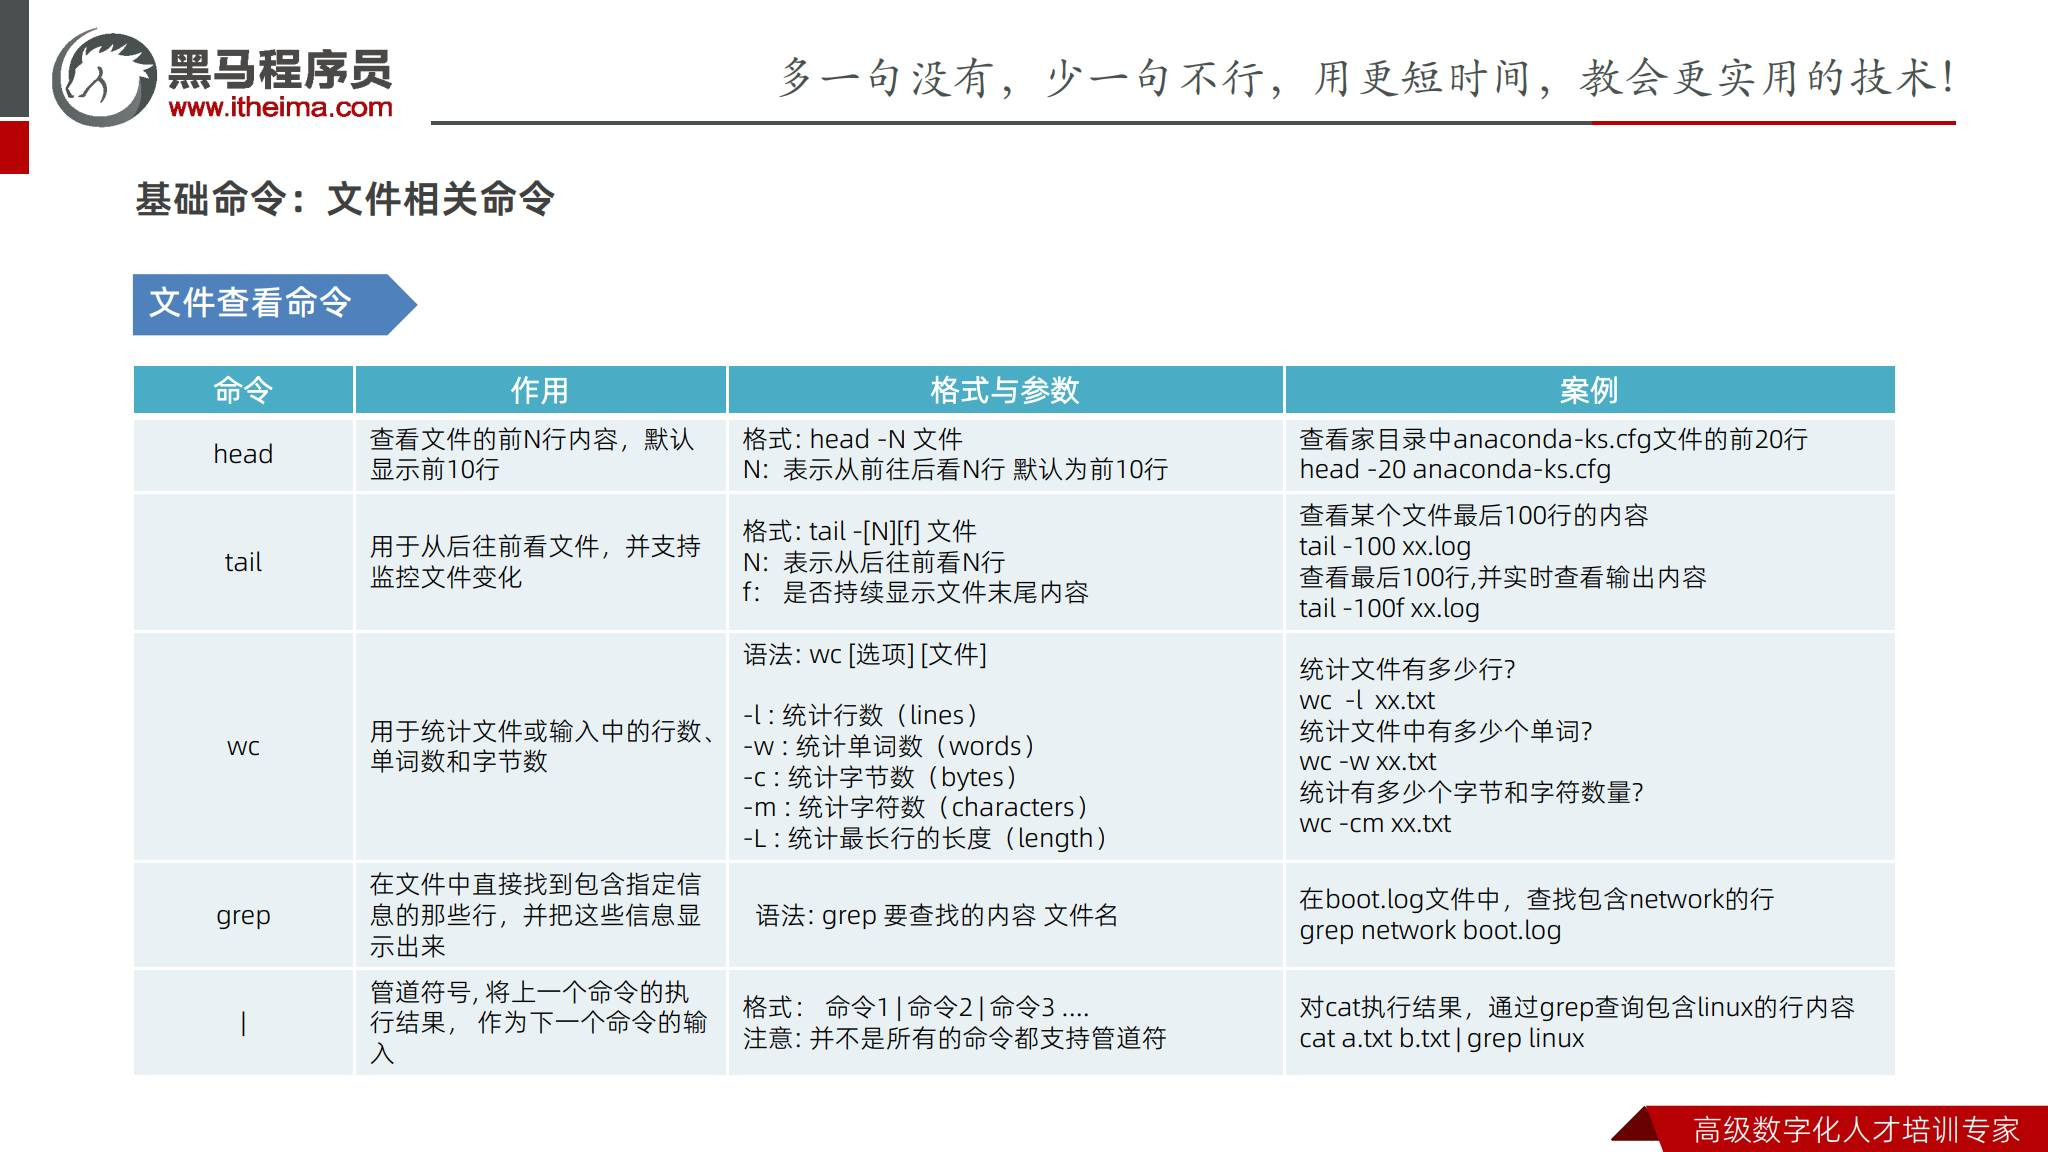

```bash
head -n 20 ~/ai-ops-lab/vim-case/app.conf
tail -n 50 ~/ai-ops-lab/vim-case/app.conf
tail -n 100 -f ~/ai-ops-lab/vim-case/app.conf
```

| 命令 | 结果 |
| --- | --- |
| `head 文件` | 默认前 10 行 |
| `head -n N 文件` | 前 N 行 |
| `tail 文件` | 默认最后 10 行 |
| `tail -n N 文件` | 最后 N 行，通常仍按原文件先后顺序输出 |
| `tail -f 文件` | 先输出末尾，再持续跟踪追加的内容 |
| `Ctrl+C` | 结束正在前台持续运行的 tail |

**整理补充：** tail 不是把最后几行倒序显示。课件中的 `head -20`、`tail -100f` 是常见 GNU 简写，笔记采用更清楚的 `-n` 写法。日志轮转导致文件被替换时，可了解 GNU tail 的 `-F`，它按文件名跟踪并重试；`-f` 默认按已打开的文件描述符跟踪。


### 6.3 wc：统计行、词、字节和字符

**原课依据：第 36-37 页。**

| 选项 | 统计内容 |
| --- | --- |
| `-l` | 换行符数量，通常用于统计文本行数 |
| `-w` | 以空白分隔的单词数量 |
| `-c` | 字节数 |
| `-m` | 按当前字符编码与 locale 统计字符数 |
| `-L` | 最长行的显示宽度，制表符等会影响结果 |

```bash
wc -l ~/ai-ops-lab/vim-case/app.conf
wc -w ~/ai-ops-lab/vim-case/app.conf
wc -cm ~/ai-ops-lab/vim-case/app.conf
```

**整理补充：** 中文 UTF-8 字符可能占多个字节，所以 `-c` 与 `-m` 不一定相等；`-w` 不做中文语义分词。文件最后一行若没有换行符，`wc -l` 不会把它计为额外一次换行。多个选项的显示顺序由 wc 规定，并非简单跟随选项顺序。


### 6.4 grep、管道与重定向

**原课依据：第 36、38-39 页；额外选项和重定向说明为整理补充。**

```bash
grep 'ERROR' app.log
grep -n 'timeout' app.log
grep -i 'error' app.log
grep -F '[INFO]' app.log
grep 'timeout' app.log | wc -l
grep 'timeout' app.log | less
```

| 写法 | 作用 |
| --- | --- |
| `grep '模式' 文件` | 显示包含匹配内容的行；默认按基本正则表达式解释 |
| `-n` | 额外显示行号 |
| `-i` | 忽略大小写 |
| `-F` | 按固定字符串匹配，例如字面的 `[INFO]` |
| `命令1 \| 命令2` | 将命令 1 的标准输出交给命令 2 的标准输入 |
| `命令 > 文件` | 把标准输出写到文件，创建或截断覆盖 |
| `命令 >> 文件` | 追加标准输出 |

课件示例：

```bash
cat a.txt b.txt | grep linux
```

管道传递的是数据流，后续命令需要能读取标准输入；例如 `cd` 需要路径参数，不会从管道自动读取目录。标准错误通常不会通过普通 `|` 传递。

**整理补充：** `grep 'timeout' | wc -l` 统计的是**匹配行数**，同一行出现 2 次 timeout 仍算 1 行；无匹配时 grep 通常返回状态 1，并不等于程序执行故障。


### 6.5 原课日志查看案例与 timeout 作业

**原课依据：第 37、39 页。** 原题查看 `/var/log/messages`，用 head、tail、less 分析，再对 `/var/log/syslog` 统计；作业要求查找含 timeout 的行、统计数量、分页查看结果。

**整理补充：** 这些文件名依系统配置而异，不保证同时存在。先查看 `/var/log`；若只启用了 systemd journal，可了解 `journalctl`，不能把缺少 syslog 文件直接当成故障。

下面用自己的小日志完成同样的技能练习，无需实际系统日志：

```bash
mkdir -p ~/ai-ops-lab/view-case
cd ~/ai-ops-lab/view-case
printf '%s\n' \
  '[INFO] service started' \
  '[ERROR] request timeout id=101' \
  '[INFO] request completed id=102' \
  '[WARN] timeout retry timeout id=103' \
  '[INFO] service stopped' > app.log

cat app.log
head -n 20 app.log
tail -n 50 app.log
wc -l -w -m app.log
grep 'timeout' app.log
grep 'timeout' app.log | wc -l
grep 'timeout' app.log | less
```

在 `less app.log` 中可输入 `/error` 搜索，但原题中的小写 error 与本例大写 ERROR 不同；本例直接用 `/ERROR`。timeout 作业预计输出 **2 行**，词出现 **3 次**；这说明“行数”和“出现次数”的区别。

**整理补充：** `printf` 的 `'%s\n'` 表示每个文本参数输出一行；这里 `>` 用于初始化练习日志，重复执行会覆盖旧样本。5 行文本结尾都有换行，`wc -l app.log` 应得到 5。


## 七、打包、压缩与解压

### 7.1 tar 选项：先理解打包与压缩

**原课依据：第 41-42、44 页。** tar 将多个文件与目录组织为归档；使用压缩选项时，再结合 gzip、bzip2 或 xz 压缩。

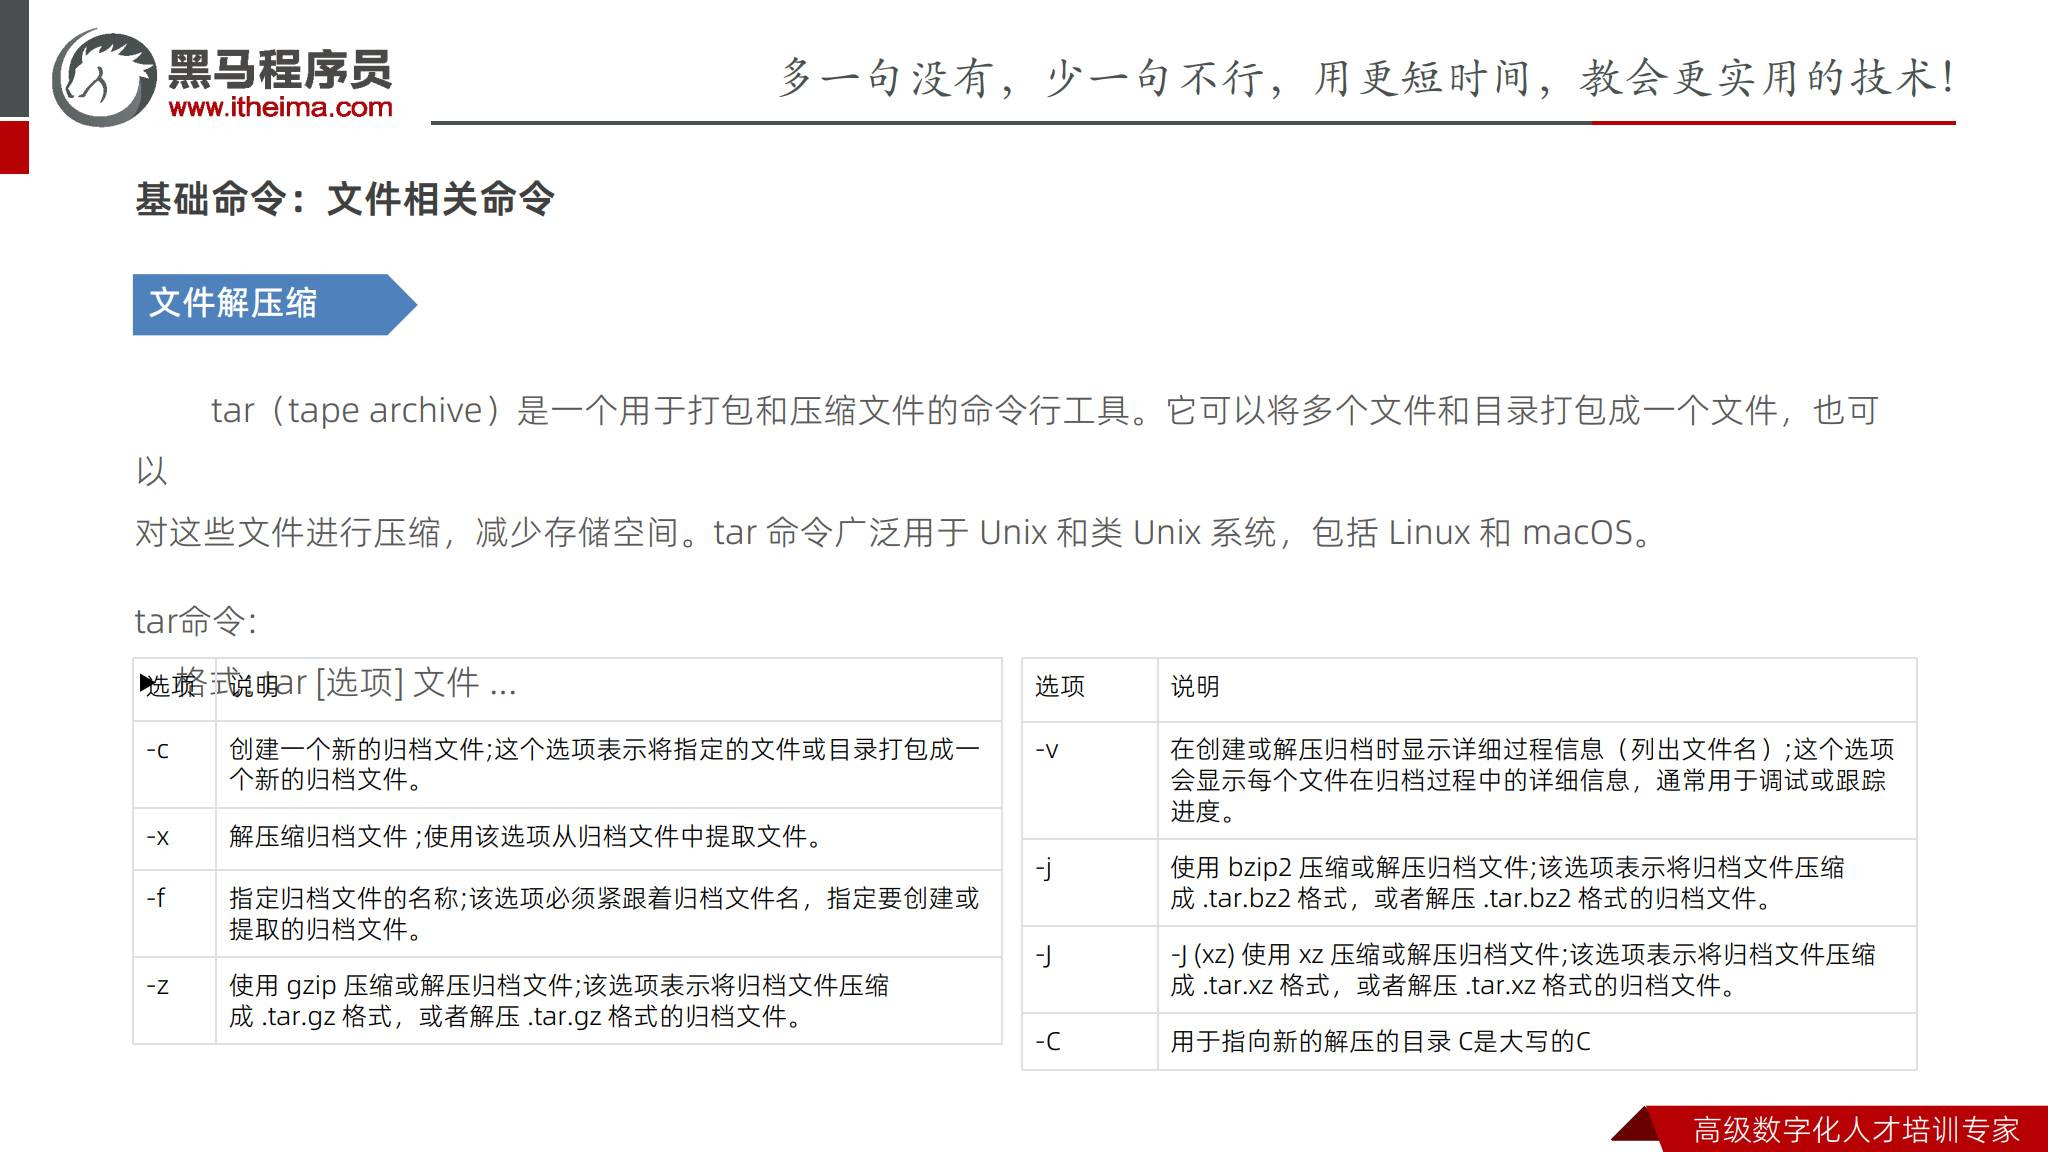

| 选项 | 含义 |
| --- | --- |
| `-c` | 创建归档 |
| `-x` | 提取归档内容 |
| `-f 归档名` | 指定归档文件，后面需要紧跟对应参数 |
| `-v` | 显示处理的文件名 |
| `-z` | 使用 gzip，对应常见 `.tar.gz` |
| `-j` | 使用 bzip2，对应常见 `.tar.bz2` |
| `-J` | 使用 xz，对应常见 `.tar.xz`，注意是大写 J |
| `-C 目录` | 在后续相关操作前切换到指定目录，创建和提取时都可用 |
| `-t` | 整理补充：列出归档内容，不提取 |

**整理补充：** `.tar` 打包通常不做压缩；把文件后缀改为 `.tar.gz` 不会自动完成压缩。`-c` 与 `-x` 是不同操作，同一次命令通常选择一种。


### 7.2 tar 常见组合与提取步骤

**原课依据：第 42、44 页。**

| 格式 | 创建 | 提取 |
| --- | --- | --- |
| tar | `tar -cvf data.tar data/` | `tar -xvf data.tar` |
| tar.gz | `tar -czvf data.tar.gz data/` | `tar -xzvf data.tar.gz` |
| tar.bz2 | `tar -cjvf data.tar.bz2 data/` | `tar -xjvf data.tar.bz2` |
| tar.xz | `tar -cJvf data.tar.xz data/` | `tar -xJvf data.tar.xz` |

**整理补充示例：** 将练习配置目录打包，归档放在被打包目录之外，先列出内容，再提取到专用目录。

```bash
cd ~/ai-ops-lab
tar -czvf vim-case.tar.gz vim-case/
tar -tzf vim-case.tar.gz
mkdir -p restore-tar
tar -xzvf vim-case.tar.gz -C restore-tar
cat restore-tar/vim-case/app.conf
```

本例提取结果是 `restore-tar/vim-case/app.conf`，因为归档里包含 vim-case 这一层。`-C` 的目标目录需要先存在；它不会自动消除包内层级。

**整理补充：** 对外来归档先查看成员路径，再选择提取目录，避免已有同名文件被覆盖。`-f` 后面的文件名是归档本身，不是要打包的源目录。


### 7.3 zip 与 unzip

**原课依据：第 43-44 页。**

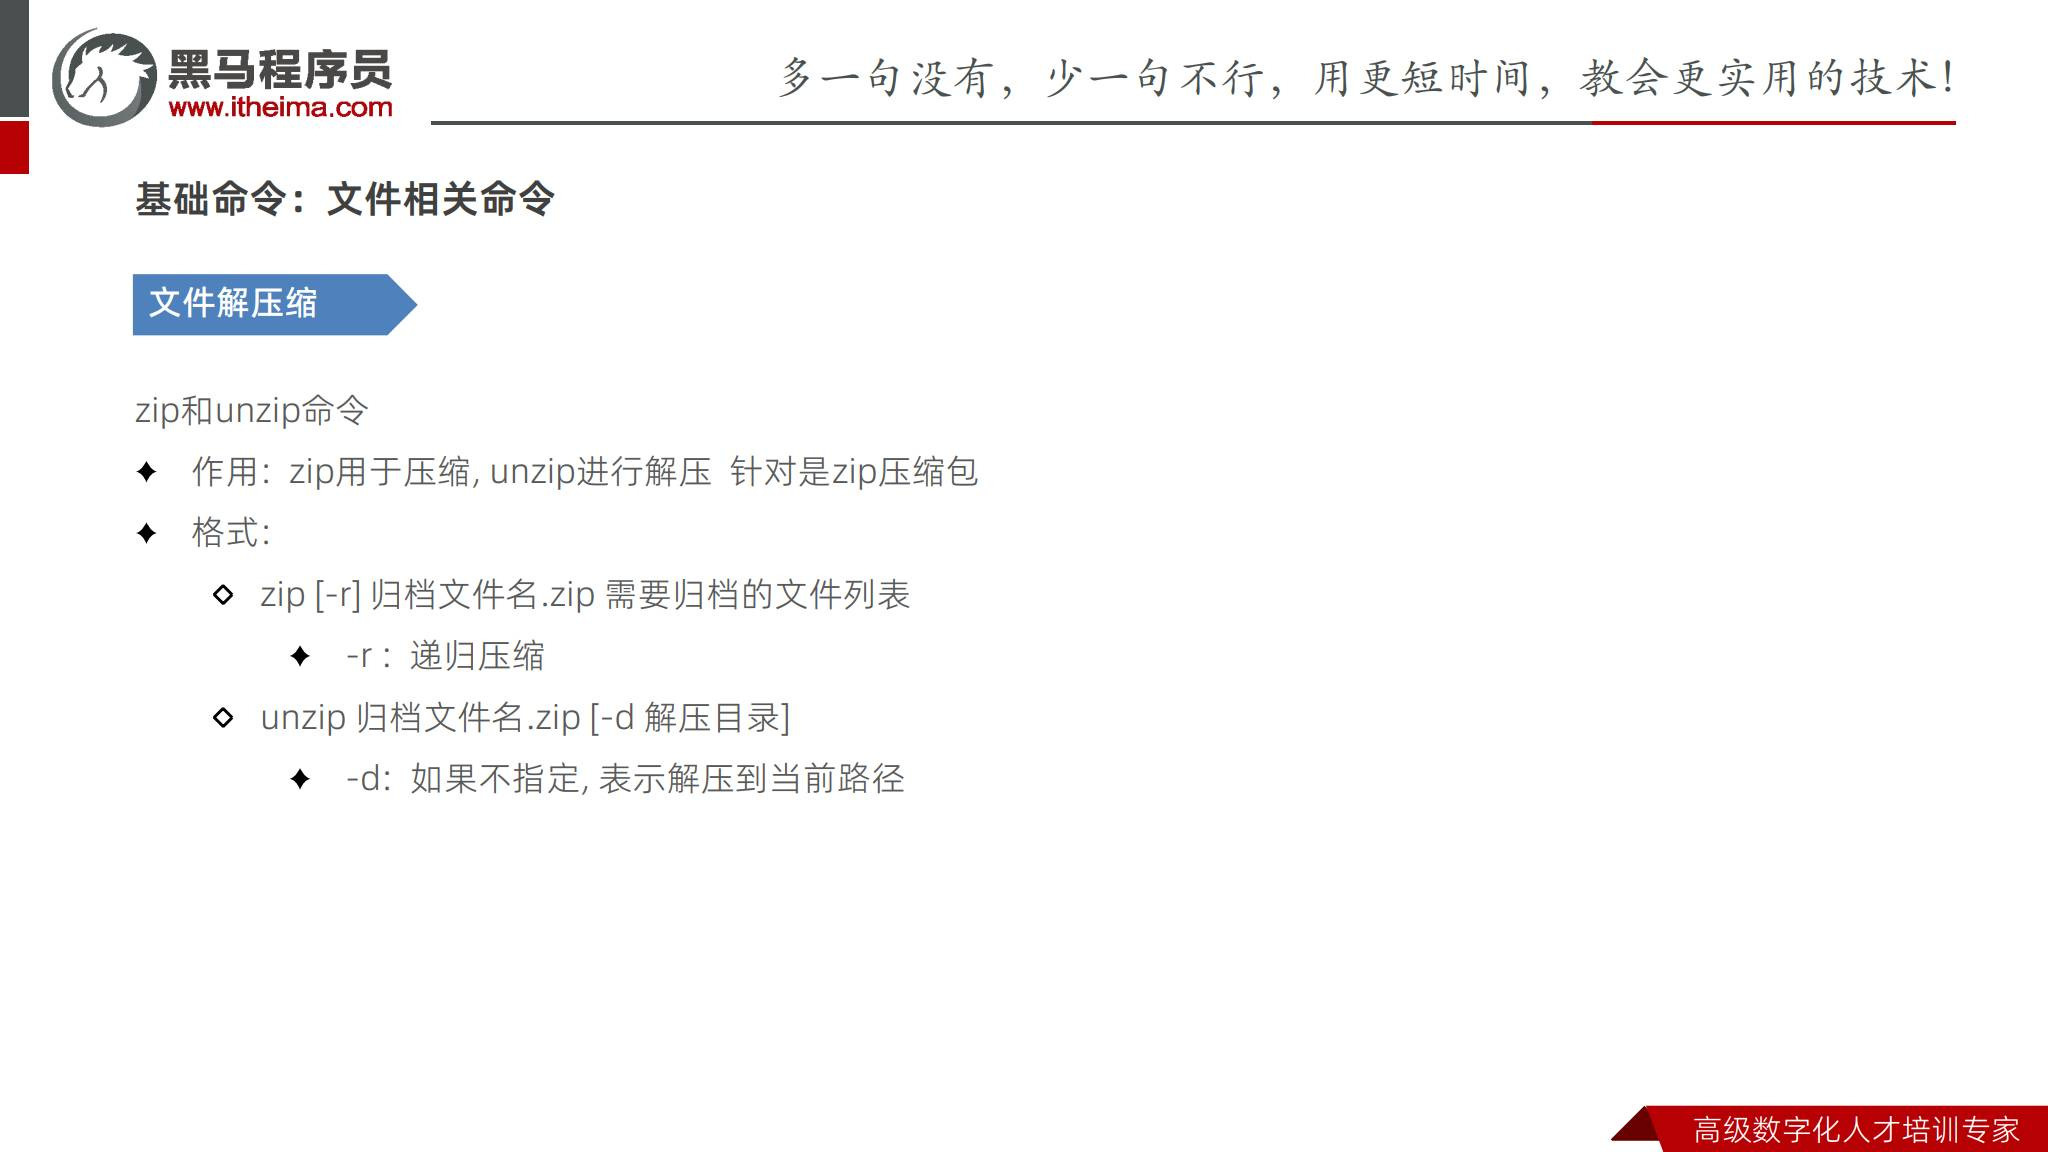

```bash
cd ~/ai-ops-lab
zip -r vim-case.zip vim-case/
unzip -l vim-case.zip
mkdir -p restore-zip
unzip vim-case.zip -d restore-zip
cat restore-zip/vim-case/app.conf
```

| 选项或操作 | 说明 |
| --- | --- |
| `zip -r 包名.zip 目录` | 递归打包压缩目录 |
| `zip 包名.zip 文件1 文件2` | 压缩多个文件 |
| `unzip 包名.zip` | 默认提取到当前目录 |
| `unzip 包名.zip -d 目标目录` | 指定提取位置 |
| `unzip -l 包名.zip` | 整理补充：先查看包内列表 |

**整理补充：** `zip`、`unzip` 不一定预装；CentOS Stream 9 中需要时可由管理员运行 `sudo dnf install zip unzip`。ZIP 在桌面系统间交换文件很常见，但不能据此假定它能完整保留所有 Linux 元数据；需要 Unix 权限等信息时，通常更适合使用 tar 类归档并核对参数。


## 八、原课综合作业：项目目录与日志管理

### 8.1 先明确原题要求与矛盾

**原课依据：第 45 页。**

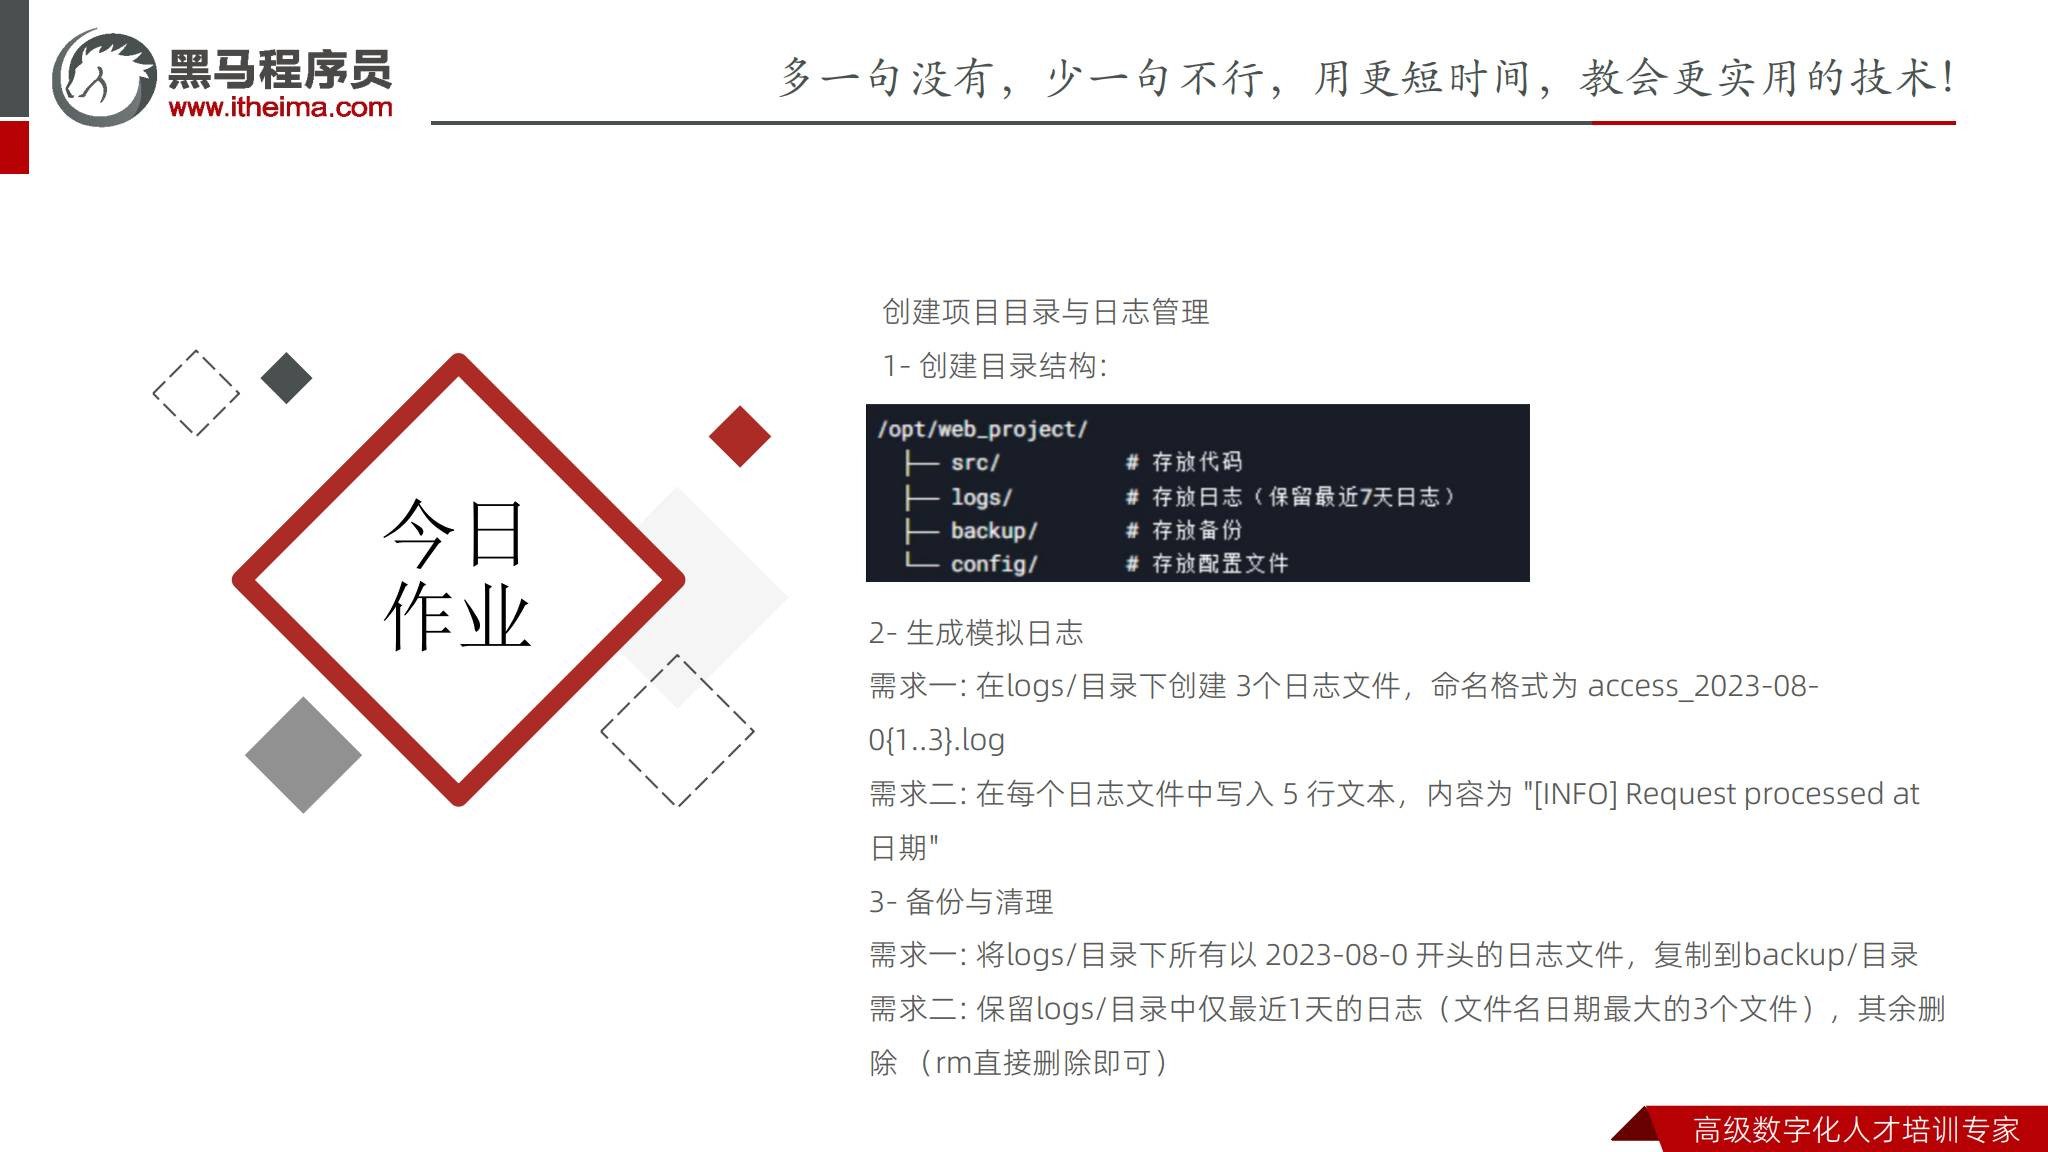

```text
/opt/web_project/
├── src/       代码
├── logs/      日志
├── backup/    备份
└── config/    配置
```

原题要求创建 3 个 `access_2023-08-0{1..3}.log`，每个写入 5 行 `[INFO] Request processed at 日期`，复制到 backup，再清理 logs。

**整理补充：** 原图的目录备注写“保留最近 7 天日志”，下面又写“仅最近 1 天（文件名日期最大的 3 个文件）”；只生成 3 个文件时，保留最大的 3 个就没有可删除对象。这里保留原题并给出两种明确的练习口径：

| 口径 | 本笔记如何处理 |
| --- | --- |
| 原题创建与备份 | 创建 3 个文件、每个 5 行、备份 3 个 |
| 补充清理练习 | 扩展为 5 个固定格式的日期文件，再保留文件名日期最新的 3 个 |

该清理练习按**文件名日期**排序，不按 mtime，也不声称等于“最近 1 天”或“最近 7 天”。路径由原题的 `/opt/web_project` 改为 `~/ai-ops-lab/web_project`。


### 8.2 创建目录、写入日志与备份

**整理补充答案：** 此案例首次执行时请使用新的 web_project 练习目录。

```bash
mkdir -p ~/ai-ops-lab/web_project/{src,logs,backup,config}
cd ~/ai-ops-lab/web_project

for day in 01 02 03; do
  file="logs/access_2023-08-${day}.log"
  touch "$file"
  for line in 1 2 3 4 5; do
    printf '[INFO] Request processed at 2023-08-%s\n' "$day"
  done > "$file"
done

wc -l logs/access_2023-08-0*.log
cp -p logs/access_2023-08-0*.log backup/
ls -l backup
```

首次执行预计每个文件 5 行，总计 **15 行**，backup 中有 **3 个**文件。

**整理补充：** Bash 的 `{src,logs,backup,config}` 是大括号展开；for 循环把重复写日志的过程写短。变量展开的路径加双引号，`>` 放在内部循环结束处，将 5 次输出集中写入当前文件。这里尚未改变日志 mtime，文件名是历史日期，mtime 则是实际写入时刻。


### 8.3 扩展清理与归档验证

**整理补充练习：** 增加 04、05 两个文件，使“保留文件名日期最新的 3 个”出现实际删除动作。

```bash
cd ~/ai-ops-lab/web_project
for day in 04 05; do
  file="logs/access_2023-08-${day}.log"
  for line in 1 2 3 4 5; do
    printf '[INFO] Request processed at 2023-08-%s\n' "$day"
  done > "$file"
done

cp -p logs/access_2023-08-0*.log backup/
ls -l logs backup
rm -i logs/access_2023-08-01.log logs/access_2023-08-02.log
wc -l logs/access_2023-08-0*.log
```

确认删除后，logs 应只保留 03、04、05 的 **3 个文件，共 15 行**；backup 应仍有 01-05 的 **5 个文件，共 25 行**。使用明确文件名复现课件要求，不把任意目录套入自动删除流程。

最后把 backup 打包，并恢复到另一目录验证：

```bash
tar -czvf backup-2023-08.tar.gz backup/
tar -tzf backup-2023-08.tar.gz
mkdir -p restore
tar -xzvf backup-2023-08.tar.gz -C restore
wc -l restore/backup/access_2023-08-0*.log
```

验证标准：原日志数量符合规则，备份文件保留，包内路径正确，恢复后的每个文件仍有 5 行。**创建了压缩包只是备份流程的一步，恢复验证才能说明它可用。**


## 九、常见错误与命令速查

### 9.1 按现象排查

**整理补充。**

| 现象 | 优先检查 |
| --- | --- |
| `No such file or directory` | 当前路径、绝对/相对路径、大小写、父目录是否存在 |
| `Not a directory` | 是否把文件当目录，或路径某一层实际是文件 |
| `Permission denied` | 身份、目录访问权限、文件读写权限，避免只靠重复加命令选项 |
| `Directory not empty` | `rmdir` 的对象是否含子目录、普通文件或隐藏项 |
| `cp: ... omitting directory` | 复制目录是否需要 `-r` |
| find 无结果或模式异常 | 搜索范围、引号、`-type`、mtime 与文件名日期是否混淆 |
| Vim 打字却执行了命令 | 是否仍在命令模式，先按 `i` 再输入文字 |
| Vim 无法退出 | 先 Esc，再选择 `:x` 保存退出或 `:q!` 丢弃退出 |
| E325 交换文件提示 | 是否有活动编辑会话，是否需要恢复，交换文件实际位置 |
| tail 一直不返回提示符 | 使用了跟踪选项，Ctrl+C 可结束 |
| grep 没有匹配 | 大小写、模式类型、文件内容；固定字符串可用 `-F` |
| tar 提示无法打开归档 | `-f` 后的归档路径、当前目录、文件是否存在 |
| 解压多出一层目录 | 包内本来包含顶层目录，先用 `tar -t` 或 `unzip -l` 查看 |
| `tree`、`zip` 找不到 | 命令未安装或 PATH 不包含它，按实际系统的软件包方式处理 |


### 9.2 高频命令速查

| 任务 | 命令示例 |
| --- | --- |
| 定位与列目录 | `pwd`、`ls -lah` |
| 返回家目录 / 上级 / 上次目录 | `cd`、`cd ..`、`cd -` |
| 创建多级目录 | `mkdir -p a/b/c` |
| 删除空目录 | `rmdir a/b/c` |
| 查看两层结构 | `tree -L 2` |
| 创建空文件 / 设置日期 | `touch a.txt`、`touch -d '3 days ago' a.txt` |
| 复制目录 / 移动文件 | `cp -r data backup`、`mv a.txt backup/` |
| 按名称查普通文件 | `find . -type f -name '*.log'` |
| 查不足 24 小时的文件 | `find . -type f -mtime -1` |
| 查大于 100 MiB 的文件 | `find . -type f -size +100M` |
| 打开第 10 行 | `vim +10 app.conf` |
| 前 20 行 / 后 50 行 | `head -n 20 app.log`、`tail -n 50 app.log` |
| 跟踪新增日志 | `tail -n 100 -f app.log` |
| 匹配并统计行 | `grep 'timeout' app.log \| wc -l` |
| 分页看匹配结果 | `grep 'timeout' app.log \| less` |
| tar.gz 创建 / 提取 | `tar -czvf data.tar.gz data/`、`tar -xzvf data.tar.gz -C restore` |
| ZIP 创建 / 提取 | `zip -r data.zip data/`、`unzip data.zip -d restore` |

`find` 的删除操作、`rm` 以及会覆盖目标的写入操作，理解路径和筛选结果后再在练习目录执行。上述代码是笔记示例，不会因打开 Notebook 自动运行。


## 十、复习题与参考答案

### 10.1 先独立回答

1. 根目录 `/`、root 家目录 `/root`、普通用户目录 `/home/alice` 有什么区别？
2. 当前目录为 `/opt/web_project` 时，`logs/a.log` 指向哪里？切换到 `/etc` 后还指向同一文件吗？
3. 如何列出当前目录的隐藏项及易读大小？`ll` 为什么可能不可用？
4. `rmdir` 为什么不能直接删除包含子目录的 family？
5. `touch` 对已有文件做什么？文件名中的日期能决定 mtime 吗？
6. 复制目录用什么参数？移动目录也必须添加同样参数吗？
7. `find . -name '*.log'` 中的引号为什么需要保留？
8. 距今 73 小时的文件能匹配 `-mtime 3`、`-mtime +3`、`-mtime +2` 中哪些条件？
9. `find -size` 的默认单位是什么？`c` 与 `M` 分别是什么单位？
10. `{}` 与 `\;` 在 `find -exec` 中各负责什么？
11. Vim 如何进入插入模式、如何回命令模式、如何保存退出？
12. E325 为什么不能一律删除 `.swp`？
13. tail 输出最后几行时，会把它们倒序吗？如何结束跟踪？
14. 一行中出现 2 次 timeout，用 `grep 'timeout' | wc -l` 计为几行？
15. tar 打包与 gzip 压缩有什么区别？`-C` 会自动去掉包内顶层目录吗？
16. 第 45 页作业中，“最新的 3 个文件”和“最近 1 天”为什么不能直接等同？


### 10.2 参考答案

| 题号 | 要点 |
| --- | --- |
| 1 | `/` 是整个目录树起点；`/root` 是 root 的家目录；`/home/alice` 通常是 alice 的家目录 |
| 2 | 原来对应 `/opt/web_project/logs/a.log`；相对路径随当前目录变化 |
| 3 | `ls -lah`；`ll` 通常是别名，环境可能未配置 |
| 4 | rmdir 只删空目录，先删除叶子目录再逐层删除父目录 |
| 5 | 默认更新已有文件的访问和修改时间，不清空内容；名字不自动设置时间戳 |
| 6 | cp 复制目录用 `-r`；mv 移动目录无需该参数 |
| 7 | 防止 Shell 先把模式展开，让 find 自己匹配名称 |
| 8 | 73 小时是 3 个完整 24 小时段，匹配 `3` 和 `+2`，不匹配 `+3` |
| 9 | 默认 512 字节块；c 是字节，M 是 1024² 字节单位，非字节单位会向上取整 |
| 10 | `{}` 替换匹配路径；`\;` 终止 exec 命令且防止 Shell 把分号提前解释 |
| 11 | i/a/o/O 进入插入；Esc 返回；命令模式输入 `:x` 并回车保存退出 |
| 12 | 也可能有另一活动编辑会话，或其中有尚需恢复的内容 |
| 13 | 不会，保留原行顺序；Ctrl+C 结束 tail 跟踪 |
| 14 | 计 1 行，这是匹配行数而不是单词出现次数 |
| 15 | tar 组织归档，gzip 压缩数据；`-C` 选择工作/提取目录，不自动去掉顶层 |
| 16 | 文件数量与经过时间是不同规则，文件名日期还可能与 mtime 不同，必须定义标准 |


## 十一、本篇完成标准与资料索引

完成本篇后，应能在自己的 Linux 练习目录中做到：

- 说清当前身份、当前工作目录和路径的含义。
- 建立并验证 game_saves、family、web_project 的目录结构。
- 创建、复制、移动文件，区分空目录删除与文件删除。
- 使用 find 同时按名称、类型、mtime、大小筛选，并解释边界。
- 在 Vim 中完成编辑、撤销、查找、保存退出，理解交换文件恢复流程。
- 对模拟日志分页查看、统计匹配行、跟踪新增内容。
- 创建 tar.gz 或 ZIP，先查看列表，再恢复到专用目录并核对内容。

| 课件段落 | 页码 |
| --- | --- |
| Linux 目录结构与总结 | 3-5 |
| 终端、导航、目录管理 | 7-10 |
| game_saves、总结与 family 作业 | 12-14 |
| 文件操作与总结 | 16-17 |
| find 与总结 | 19-20 |
| 日志案例与查找作业 | 22-23 |
| vi/vim、模式、保存与总结 | 25-31 |
| 交换文件问题 | 33 |
| 查看命令、案例、总结与作业 | 35-39 |
| tar、ZIP、总结与项目作业 | 41-45 |

**整理补充核对入口：** 在实际 Linux 环境可阅读 `man find`、`man touch`、`man cp`、`man wc`、`man tar`；Vim 内可使用 `:help recovery`、`:help :x`、`:help :substitute`。本笔记关于 GNU find 的单位与取整规则已结合本机 GNU findutils 4.9.0 手册及样本命令核对。软件版本不同，应以所在环境的帮助为准。

下一篇 03 对应《3-0基础带你入行AI Linux运维_项目部署上线.pdf》，进入项目节点规划、组件部署及应用上线。
